# Report 1: Fuzzy C-Means on WDBC (Breast Cancer Wisconsin Diagnostic)

## Step 1: Load the raw data and save it as a CSV with named columns

Source: `data/wdbc/wdbc.data` (UCI). The raw file has no header.
Column order follows `wdbc.names`, section 7: field 1 is the ID, field 2 is the diagnosis (M/B),
fields 3-12 are the means, 13-22 the standard errors, and 23-32 the "worst" values of the 10 nucleus features.


In [1]:
from pathlib import Path
import pandas as pd

# Paths are relative to this notebook (Reports/Report 1/src/wdbc/)
REPORT_DIR = Path("../..")
DATA_DIR = REPORT_DIR / "data" / "wdbc"
OUT_DIR = REPORT_DIR / "data" / "wdbc"
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Column names, taken from wdbc.names (section 7)
base = ["radius", "texture", "perimeter", "area", "smoothness",
        "compactness", "concavity", "concave_points", "symmetry",
        "fractal_dimension"]
columns = ["id", "diagnosis"] + [f"{f}_{s}" for s in ("mean", "se", "worst") for f in base]

df = pd.read_csv(DATA_DIR / "wdbc.data", header=None, names=columns)

# Sanity checks (expected values from wdbc.names)
print("shape:", df.shape)                                        # expect (569, 32)
print("missing values:", df.isna().sum().sum())                  # expect 0
print("duplicate ids:", df["id"].duplicated().sum())             # expect 0
print("duplicate feature rows:", df.duplicated(subset=columns[2:]).sum())
print(df["diagnosis"].value_counts())                            # expect B 357, M 212

df.to_csv(OUT_DIR / "wdbc_clean.csv", index=False)
print("saved:", (OUT_DIR / "wdbc_clean.csv").resolve())

shape: (569, 32)
missing values: 0
duplicate ids: 0
duplicate feature rows: 0
diagnosis
B    357
M    212
Name: count, dtype: int64
saved: /home/stefy/Work/University/Master/Anul I/Metode Avansate de Analiza a Datelor/Reports/Report 1/data/wdbc/wdbc_clean.csv


## Step 2: Exploratory look at the features

Goal: measure the properties of the 30 features before choosing feature set, scaling and transformations.
Nothing is decided here; the outputs are evidence for the choices in Step 3.

- 2a: summary statistics (ranges and scales of the features)
- 2b: skewness of each feature
- 2c: Pearson (linear) and Spearman (rank, monotonic) correlation matrices between features
- 2d: distribution of each feature (boxplots on standardized values, for comparability only)
- 2e: PCA explained variance (how much independent information the 30 features carry)

In [3]:
import numpy as np
import matplotlib.pyplot as plt

FIG_DIR = REPORT_DIR / "figures" / "wdbc"
FIG_DIR.mkdir(parents=True, exist_ok=True)

feature_cols = columns[2:]
X = df[feature_cols]

### 2a: Summary statistics

In [4]:
summary = X.describe().T
summary.to_csv(OUT_DIR / "wdbc_summary.csv")

print("smallest std:", summary["std"].idxmin(), f"{summary['std'].min():.6g}")
print("largest std: ", summary["std"].idxmax(), f"{summary['std'].max():.6g}")
print("ratio largest/smallest std:", f"{summary['std'].max() / summary['std'].min():.3g}")
summary

smallest std: fractal_dimension_se 0.00264607
largest std:  area_worst 569.357
ratio largest/smallest std: 2.15e+05


,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave_points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


### 2b: Skewness

In [5]:
skew = X.skew().sort_values(ascending=False).rename("skewness")
skew.to_csv(OUT_DIR / "wdbc_skewness.csv")

# Common rule of thumb: |skew| < 0.5 roughly symmetric, 0.5-1 moderate, > 1 strong
print("features with |skew| > 1:", (skew.abs() > 1).sum(), "of", len(skew))
skew

features with |skew| > 1: 22 of 30


area_se                    5.447186
concavity_se               5.110463
fractal_dimension_se       3.923969
perimeter_se               3.443615
radius_se                  3.088612
smoothness_se              2.314450
symmetry_se                2.195133
compactness_se             1.902221
area_worst                 1.859373
fractal_dimension_worst    1.662579
texture_se                 1.646444
area_mean                  1.645732
compactness_worst          1.473555
concave_points_se          1.444678
symmetry_worst             1.433928
concavity_mean             1.401180
fractal_dimension_mean     1.304489
compactness_mean           1.190123
concave_points_mean        1.171180
concavity_worst            1.150237
perimeter_worst            1.128164
radius_worst               1.103115
perimeter_mean             0.990650
radius_mean                0.942380
symmetry_mean              0.725609
texture_mean               0.650450
texture_worst              0.498321
concave_points_worst       0

### 2c: Correlation matrices (Pearson and Spearman)

Pearson measures linear association on the raw values; Spearman is Pearson computed on ranks, so it measures
monotonic association and is less affected by skewness and outliers. Comparing the two shows where they differ.

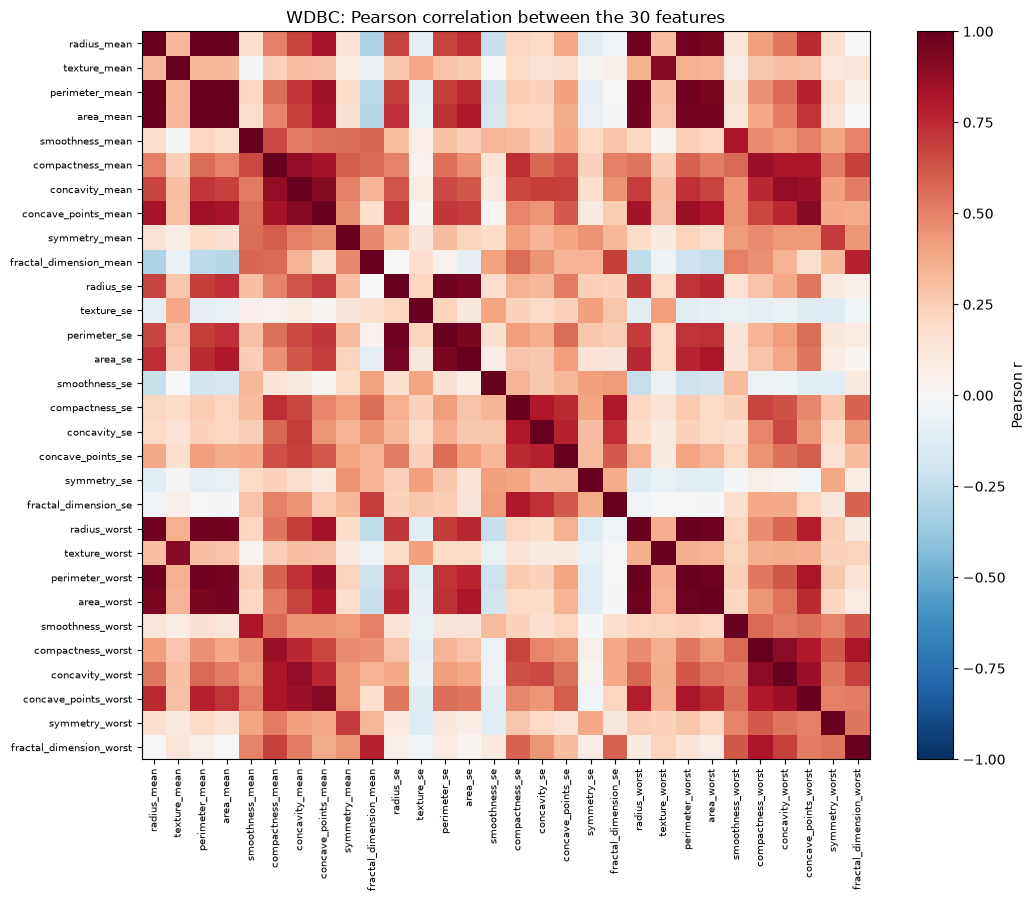

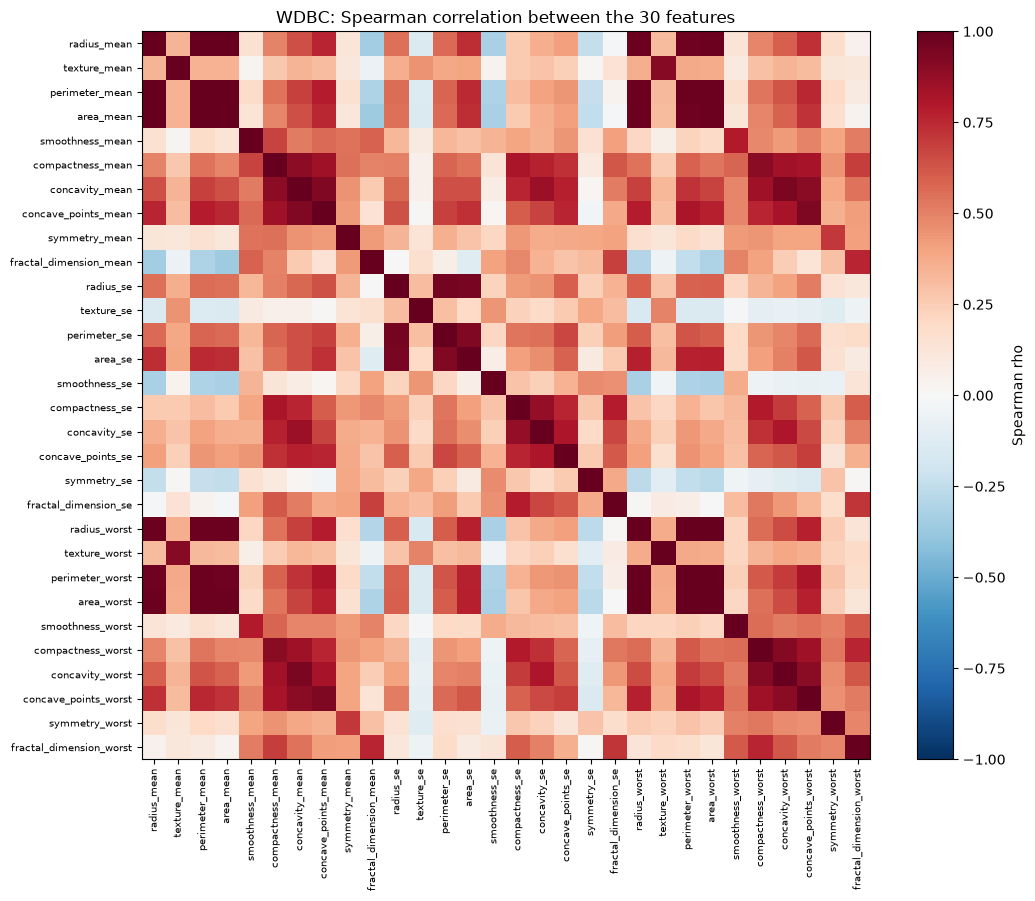

pearson: pairs with |r| > 0.9: 21 of 435
spearman: pairs with |rho| > 0.9: 26 of 435

pairs above the threshold under either method:


,,pearson,spearman,difference
radius_mean,perimeter_mean,0.997855,0.997802,-0.000054
radius_worst,perimeter_worst,0.993708,0.993548,-0.000160
radius_mean,area_mean,0.987357,0.999602,0.012245
perimeter_mean,area_mean,0.986507,0.997068,0.010561
radius_worst,area_worst,0.984015,0.998891,0.014876
perimeter_worst,area_worst,0.977578,0.992433,0.014855
radius_se,perimeter_se,0.972794,0.957728,-0.015065
perimeter_mean,perimeter_worst,0.970387,0.978980,0.008593
radius_mean,radius_worst,0.969539,0.978604,0.009065
perimeter_mean,radius_worst,0.969476,0.981244,0.011768


In [6]:
THRESHOLD = 0.9
corrs = {m: X.corr(method=m) for m in ("pearson", "spearman")}
symbol = {"pearson": "r", "spearman": "rho"}

for method, corr in corrs.items():
    corr.to_csv(OUT_DIR / f"wdbc_correlation_{method}.csv")

    fig, ax = plt.subplots(figsize=(11, 9))
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(feature_cols)), feature_cols, rotation=90, fontsize=7)
    ax.set_yticks(range(len(feature_cols)), feature_cols, fontsize=7)
    fig.colorbar(im, ax=ax, label=f"{method.capitalize()} {symbol[method]}")
    ax.set_title(f"WDBC: {method.capitalize()} correlation between the 30 features")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"wdbc_correlation_{method}.png", dpi=200)
    plt.show()

# Side-by-side table of all feature pairs (upper triangle), to check the heatmaps numerically
mask = np.triu(np.ones(corrs["pearson"].shape, dtype=bool), k=1)
pairs = pd.DataFrame({m: c.where(mask).stack().dropna() for m, c in corrs.items()})  # 30*29/2 = 435 pairs
pairs["difference"] = pairs["spearman"] - pairs["pearson"]
pairs.to_csv(OUT_DIR / "wdbc_correlation_pairs.csv")

for method in corrs:
    print(f"{method}: pairs with |{symbol[method]}| > {THRESHOLD}:", (pairs[method].abs() > THRESHOLD).sum(), "of", len(pairs))

print("\npairs above the threshold under either method:")
pairs[(pairs["pearson"].abs() > THRESHOLD) | (pairs["spearman"].abs() > THRESHOLD)].sort_values("pearson", ascending=False)

### 2d: Feature distributions

Values are z-scored here **only to put all features on one axis**; this is not the preprocessing decision.

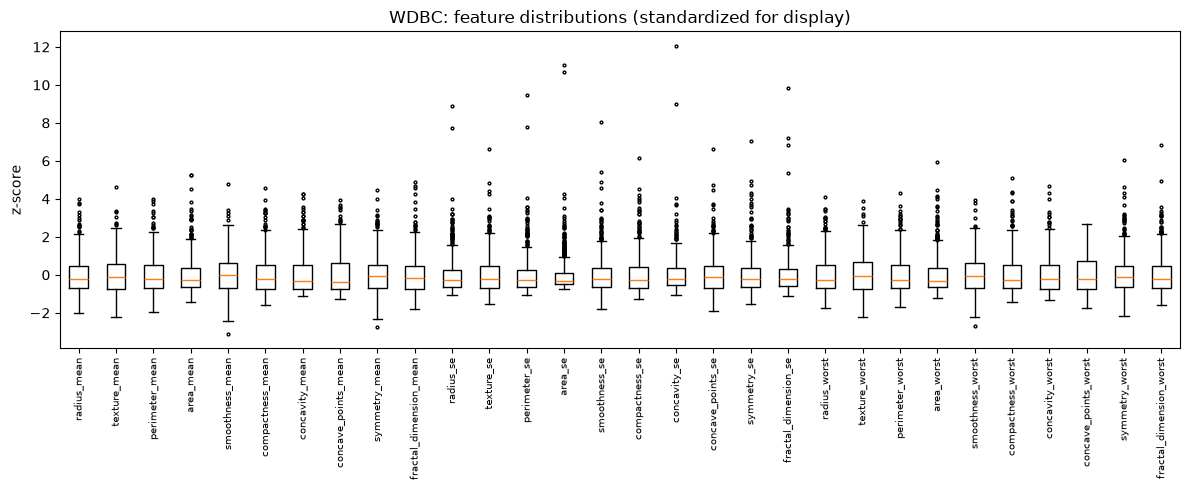

rows with at least one feature outside the whiskers: 171 of 569


area_se                    65
radius_se                  38
perimeter_se               38
area_worst                 35
smoothness_se              30
fractal_dimension_se       28
compactness_se             28
symmetry_se                27
area_mean                  25
fractal_dimension_worst    24
symmetry_worst             23
concavity_se               22
texture_se                 20
concave_points_se          19
concavity_mean             18
radius_worst               17
compactness_worst          16
compactness_mean           16
symmetry_mean              15
fractal_dimension_mean     15
perimeter_worst            15
radius_mean                14
perimeter_mean             13
concavity_worst            12
concave_points_mean        10
texture_mean                7
smoothness_worst            7
smoothness_mean             6
texture_worst               5
concave_points_worst        0
Name: n_outliers_1.5IQR, dtype: int64

In [7]:
Z = (X - X.mean()) / X.std()

fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot(Z.values, tick_labels=feature_cols, whis=1.5, flierprops={"markersize": 2})
ax.set_xticklabels(feature_cols, rotation=90, fontsize=7)
ax.set_ylabel("z-score")
ax.set_title("WDBC: feature distributions (standardized for display)")
fig.tight_layout()
fig.savefig(FIG_DIR / "wdbc_boxplots.png", dpi=200)
plt.show()

# Count of points outside the 1.5*IQR whiskers, per feature
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
outliers = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).sum().sort_values(ascending=False).rename("n_outliers_1.5IQR")
outliers.to_csv(OUT_DIR / "wdbc_outlier_counts.csv")
print("rows with at least one feature outside the whiskers:",
      ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).any(axis=1).sum(), "of", len(X))
outliers

### 2e: PCA explained variance

PCA on the **correlation matrix** (equivalent to PCA on z-scored features), so that features with large units
(e.g. area) do not dominate. Eigenvalues are the variances of the principal components; their share of the total
(= 30, the number of features) is the explained variance. Computed directly with NumPy so every step is visible.
Exploration only: clustering is not run on these components.

components needed for 80% of the variance: 5
components needed for 90% of the variance: 7
components needed for 95% of the variance: 10
components needed for 99% of the variance: 17
components with eigenvalue > 1 (Kaiser criterion): 6


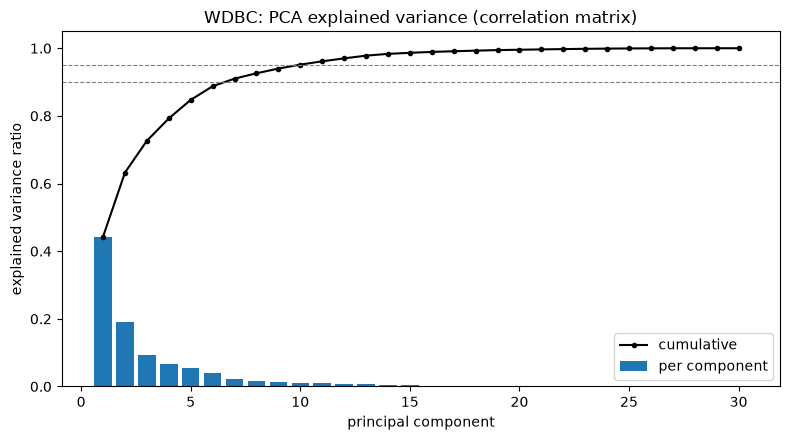

,component,eigenvalue,explained_variance_ratio,cumulative
0,1,13.281608,0.442720,0.442720
1,2,5.691355,0.189712,0.632432
2,3,2.817949,0.093932,0.726364
3,4,1.980640,0.066021,0.792385
4,5,1.648731,0.054958,0.847343
5,6,1.207357,0.040245,0.887588
6,7,0.675220,0.022507,0.910095
7,8,0.476617,0.015887,0.925983
8,9,0.416895,0.013896,0.939879
9,10,0.350693,0.011690,0.951569


In [8]:
R = X.corr(method="pearson").to_numpy()
eigvals = np.linalg.eigvalsh(R)[::-1]          # symmetric matrix -> real eigenvalues, sorted descending

pca = pd.DataFrame({
    "component": np.arange(1, len(eigvals) + 1),
    "eigenvalue": eigvals,
    "explained_variance_ratio": eigvals / eigvals.sum(),
})
pca["cumulative"] = pca["explained_variance_ratio"].cumsum()
pca.to_csv(OUT_DIR / "wdbc_pca_explained_variance.csv", index=False)

for level in (0.80, 0.90, 0.95, 0.99):
    k = int((pca["cumulative"] >= level).idxmax()) + 1
    print(f"components needed for {level:.0%} of the variance: {k}")
print("components with eigenvalue > 1 (Kaiser criterion):", (pca["eigenvalue"] > 1).sum())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(pca["component"], pca["explained_variance_ratio"], label="per component")
ax.plot(pca["component"], pca["cumulative"], marker="o", markersize=3, color="black", label="cumulative")
for level in (0.90, 0.95):
    ax.axhline(level, linestyle="--", linewidth=0.8, color="grey")
ax.set_xlabel("principal component")
ax.set_ylabel("explained variance ratio")
ax.set_title("WDBC: PCA explained variance (correlation matrix)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "wdbc_pca_explained_variance.png", dpi=200)
plt.show()

pca.head(10)

## Step 3: Preprocessing variants

Three preprocessing pipelines are built and compared; FCM is run on each of them separately later:

- **z-score**: (x - mean) / std, every feature gets mean 0 and variance 1 (population std, ddof = 0)
- **min-max**: (x - min) / (max - min), every feature is mapped to [0, 1]
- **log1p + z-score**: log(1 + x) applied first (some features have minimum 0), then z-score;
  compresses the long right tails found in Step 2b

Decision (a): all 30 features are used (the dataset as published; the redundancy of the size features
is discussed, not removed). Decision (c): the log transform is used as a variant, not a replacement; z-score is the main pipeline.

The diagnosis is kept aside as `y` and is **not** used by any preprocessing or clustering step, only for evaluation at the end.

In [9]:
FEATURES = feature_cols                 # decision (a): all 30 features
X_raw = df[FEATURES].to_numpy(dtype=float)
y = df["diagnosis"].to_numpy()          # kept aside, evaluation only

def zscore(A):
    return (A - A.mean(axis=0)) / A.std(axis=0)

def minmax(A):
    return (A - A.min(axis=0)) / (A.max(axis=0) - A.min(axis=0))

assert (X_raw >= 0).all(), "log1p needs non-negative values"

variants = {
    "zscore": zscore(X_raw),
    "minmax": minmax(X_raw),
    "log1p_zscore": zscore(np.log1p(X_raw)),
}

for name, A in variants.items():
    out = pd.DataFrame(A, columns=FEATURES)
    out.insert(0, "diagnosis", y)
    out.to_csv(OUT_DIR / f"wdbc_{name}.csv", index=False)
    print(f"{name:12s} shape={A.shape}  mean range=[{A.mean(0).min():.3f}, {A.mean(0).max():.3f}]  "
          f"std range=[{A.std(0).min():.3f}, {A.std(0).max():.3f}]  "
          f"value range=[{A.min():.3f}, {A.max():.3f}]")

# Effect of log1p on the skewness measured in Step 2b
skew_log = pd.DataFrame(np.log1p(X_raw), columns=FEATURES).skew()
print("\nfeatures with |skew| > 1:  raw =", (X.skew().abs() > 1).sum(), "  after log1p =", (skew_log.abs() > 1).sum())


zscore       shape=(569, 30)  mean range=[-0.000, 0.000]  std range=[1.000, 1.000]  value range=[-3.112, 12.073]
minmax       shape=(569, 30)  mean range=[0.063, 0.404]  std range=[0.076, 0.226]  value range=[0.000, 1.000]
log1p_zscore shape=(569, 30)  mean range=[-0.000, 0.000]  std range=[1.000, 1.000]  value range=[-3.178, 11.024]

features with |skew| > 1:  raw = 22   after log1p = 15


### 3a: How much each feature weighs in the distance

For Euclidean distance, the expected squared distance between two random points is 2 * sum of the feature variances.
So each feature's **share of the total variance** is its average share in the squared distances FCM works with.
Under z-score and log1p + z-score every share is 1/30 by construction; under min-max the shares depend on each feature's distribution.

In [10]:
weights = pd.DataFrame({
    name: pd.Series(A.var(axis=0) / A.var(axis=0).sum(), index=FEATURES)
    for name, A in variants.items()
})
weights["raw (unscaled)"] = pd.Series(X_raw.var(axis=0) / X_raw.var(axis=0).sum(), index=FEATURES)
weights = weights.sort_values("minmax", ascending=False)
weights.to_csv(OUT_DIR / "wdbc_scaling_variance_share.csv")

print("max/min variance share under min-max:", f"{weights['minmax'].max() / weights['minmax'].min():.2f}")
print("top 3 features in the raw data hold", f"{weights['raw (unscaled)'].nlargest(3).sum():.1%}", "of the variance")
weights.round(4)

max/min variance share under min-max: 8.78
top 3 features in the raw data hold 99.6% of the variance


,zscore,minmax,log1p_zscore,raw (unscaled)
concave_points_worst,0.0333,0.0818,0.0333,0.0000
concave_points_mean,0.0333,0.0596,0.0333,0.0000
concavity_mean,0.0333,0.0559,0.0333,0.0000
radius_worst,0.0333,0.0474,0.0333,0.0001
perimeter_mean,0.0333,0.0452,0.0333,0.0013
perimeter_worst,0.0333,0.0449,0.0333,0.0025
radius_mean,0.0333,0.0446,0.0333,0.0000
concavity_worst,0.0333,0.0445,0.0333,0.0000
texture_worst,0.0333,0.0430,0.0333,0.0001
compactness_mean,0.0333,0.0421,0.0333,0.0000


### 3b: Distributions after each preprocessing variant

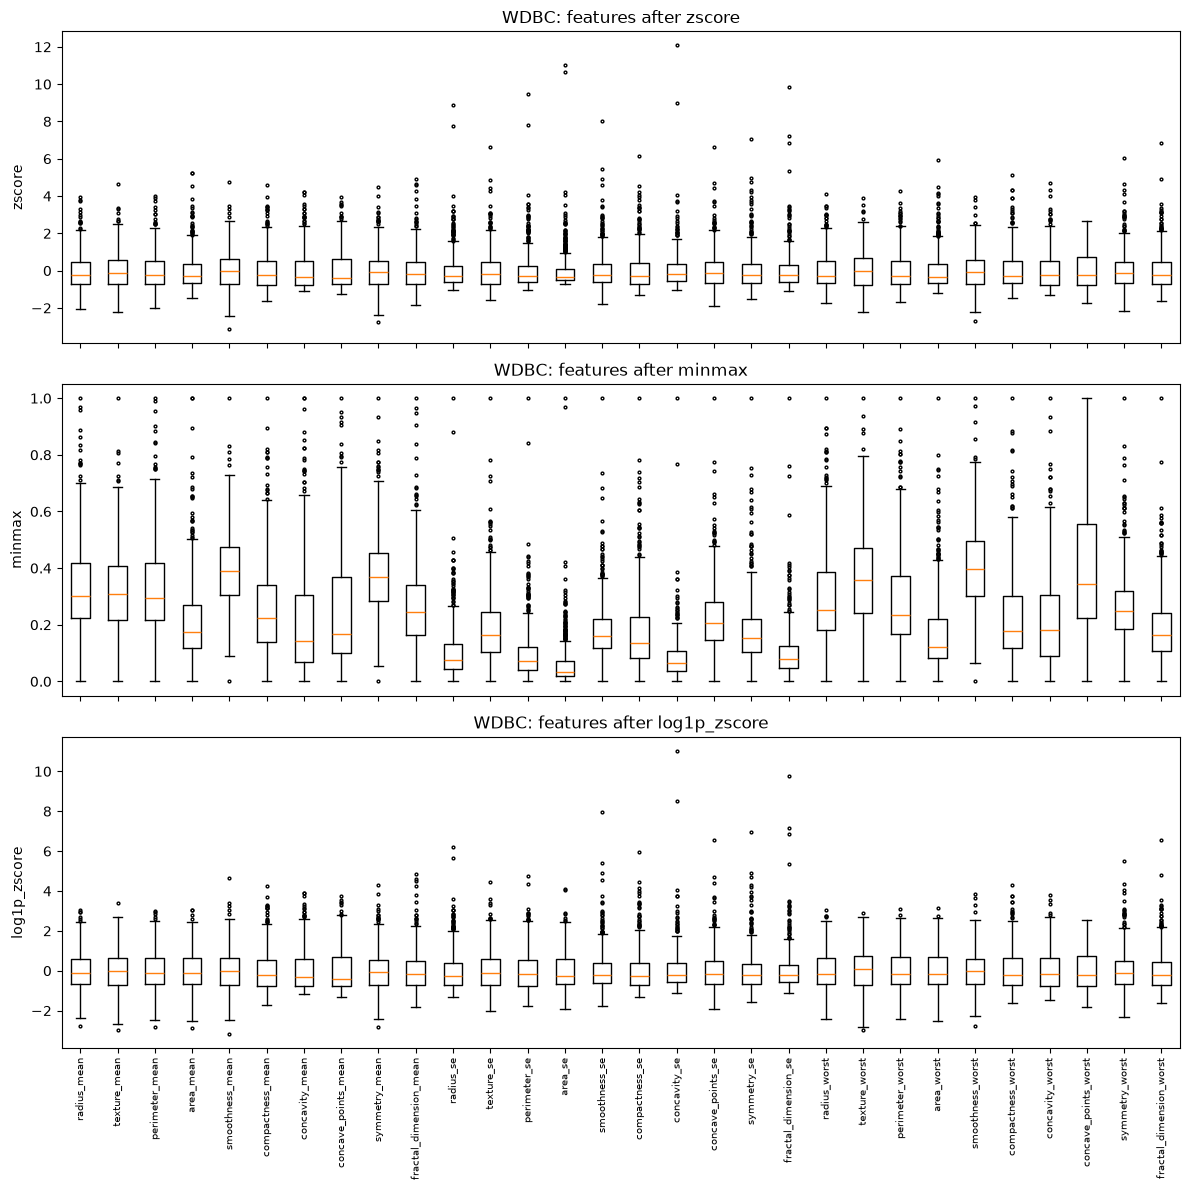

In [11]:
fig, axes = plt.subplots(len(variants), 1, figsize=(12, 4 * len(variants)), sharex=True)
for ax, (name, A) in zip(axes, variants.items()):
    ax.boxplot(A, whis=1.5, flierprops={"markersize": 2})
    ax.set_ylabel(name)
    ax.set_title(f"WDBC: features after {name}")
axes[-1].set_xticks(range(1, len(FEATURES) + 1), FEATURES, rotation=90, fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "wdbc_scaling_comparison.png", dpi=200)
plt.show()

## Step 4: FCM implementation and cross-check

FCM and the validity indices are implemented in `src/fcm.py` (plain NumPy, following lecture 05a, slides 16-17 and 75-82),
so the same code is shared by all three datasets.

Before using it, the implementation is checked against an independent one, `skfuzzy.cluster.cmeans` (scikit-fuzzy),
by giving both **the same data and the same initial partition U0**. If they agree, the final U, V and J must coincide
up to floating-point error. A second check: FCM is an alternating minimisation, so J must never increase between iterations.

Requires `pip install scikit-fuzzy` (used only for this check).

In [12]:
import sys
sys.path.insert(0, "..")          # make src/ importable (this notebook is in src/wdbc/)

import importlib
import fcm
importlib.reload(fcm)             # picks up edits to fcm.py without restarting the kernel

SEED = 42
FCM_EPS, FCM_MAX_ITER = 1e-5, 1000

In [13]:
import skfuzzy

Xc = variants["zscore"]
c_check, m_check = 2, 2.0

ours = fcm.fcm(Xc, c=c_check, m=m_check, eps=FCM_EPS, max_iter=FCM_MAX_ITER, seed=SEED)

# scikit-fuzzy expects data as features x samples, and the same initial partition
cntr, u, u0, d, jm, p, fpc = skfuzzy.cluster.cmeans(
    Xc.T, c=c_check, m=m_check, error=FCM_EPS, maxiter=FCM_MAX_ITER, init=ours.U0
)

check = pd.Series({
    "iterations (ours)": ours.n_iter,
    "iterations (skfuzzy)": p,
    "converged (ours)": ours.converged,
    "max |U_ours - U_skfuzzy|": np.abs(ours.U - u).max(),
    "max |V_ours - V_skfuzzy|": np.abs(ours.V - cntr).max(),
    "J (ours)": ours.J,
    "J (skfuzzy)": jm[-1],
    "PC (ours)": fcm.partition_coefficient(ours.U),
    "PC (skfuzzy)": fpc,
    "J never increases (ours)": bool(np.all(np.diff(ours.J_history) <= 1e-9 * ours.J_history[0])),
})
check.to_csv(OUT_DIR / "wdbc_fcm_crosscheck.csv", header=["value"])
check

iterations (ours)                    27
iterations (skfuzzy)                 27
converged (ours)                   True
max |U_ours - U_skfuzzy|            0.0
max |V_ours - V_skfuzzy|            0.0
J (ours)                    8021.475266
J (skfuzzy)                 8021.475266
PC (ours)                      0.655894
PC (skfuzzy)                   0.655894
J never increases (ours)           True
dtype: object

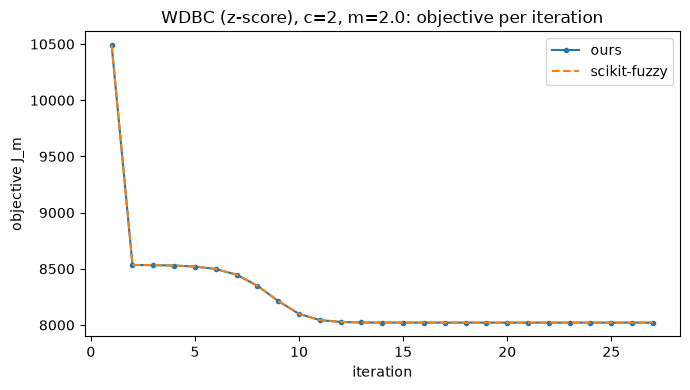

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(ours.J_history) + 1), ours.J_history, marker="o", markersize=3, label="ours")
ax.plot(range(1, len(jm) + 1), jm, linestyle="--", label="scikit-fuzzy")
ax.set_xlabel("iteration")
ax.set_ylabel("objective J_m")
ax.set_title(f"WDBC (z-score), c={c_check}, m={m_check}: objective per iteration")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "wdbc_fcm_crosscheck_objective.png", dpi=200)
plt.show()

## Step 5: Choosing the number of clusters c

For each preprocessing variant and each c = 2 ... 10, FCM is run with m = 2 from `N_INIT` = 10 random initial partitions
(seeds `SEED`, `SEED + 1`, ...); the run with the lowest objective J is kept. The diagnosis is **not** used here.

Logged per (variant, c): the validity indices, J, iterations, how many of the 10 starts reached the same minimum
(`n_at_best`, a stability check) and how many did not converge.

Reading the indices (lecture 05a, slides 76-82):

| index | best | range / note |
|---|---|---|
| PC | max | 1/c (uniform) ... 1 (crisp) |
| NPC | max | 0 (uniform) ... 1 (crisp), removes the dependence of PC's range on c |
| PE | min | 0 (crisp) ... ln c (uniform) |
| NPE | min | 0 (crisp) ... 1 (uniform) |
| XB | min | compactness / (n * separation of the two closest prototypes) |
| FS | min | compactness - separation from the grand mean; not in the slides |

PC and PE have a range that depends on c, which tends to favour small c; this is why the normalised versions are also shown.
J and FS are in the units of the (scaled) data, so their values are not comparable across preprocessing variants, only across c.

In [15]:
C_RANGE = range(2, 11)
M_DEFAULT = 2.0
N_INIT = 10

rows = []
best_runs = {}                         # (variant, c) -> best FCMResult, reused in later steps
for name, A in variants.items():
    for c in C_RANGE:
        best, info = fcm.fcm_multistart(A, c, m=M_DEFAULT, n_init=N_INIT, seed=SEED,
                                        eps=FCM_EPS, max_iter=FCM_MAX_ITER)
        best_runs[(name, c)] = best
        rows.append({
            "variant": name, "c": c,
            **fcm.validity_indices(A, best, M_DEFAULT),
            "J": best.J, "iterations": best.n_iter,
            "n_at_best": info["n_at_best"], "n_not_converged": info["n_not_converged"],
            "J_worst_start": info["J_all"].max(),
        })
        print(f"{name:12s} c={c:2d}  J={best.J:12.4f}  iter={best.n_iter:4d}  "
              f"starts at best minimum={info['n_at_best']}/{N_INIT}  not converged={info['n_not_converged']}")

c_sel = pd.DataFrame(rows)
c_sel.to_csv(OUT_DIR / "wdbc_c_selection.csv", index=False)

zscore       c= 2  J=   8021.4753  iter=  26  starts at best minimum=10/10  not converged=0
zscore       c= 3  J=   5333.6812  iter= 109  starts at best minimum=10/10  not converged=0
zscore       c= 4  J=   3997.4526  iter= 239  starts at best minimum=10/10  not converged=0
zscore       c= 5  J=   3195.1440  iter= 735  starts at best minimum=10/10  not converged=2
zscore       c= 6  J=   2664.9304  iter= 280  starts at best minimum=10/10  not converged=0
zscore       c= 7  J=   2281.7179  iter=1000  starts at best minimum=10/10  not converged=10
zscore       c= 8  J=   1997.1700  iter= 786  starts at best minimum=10/10  not converged=0
zscore       c= 9  J=   1774.9194  iter= 555  starts at best minimum=10/10  not converged=0
zscore       c=10  J=   1597.4041  iter=1000  starts at best minimum=9/10  not converged=10
minmax       c= 2  J=    157.1797  iter=  22  starts at best minimum=10/10  not converged=0
minmax       c= 3  J=    104.6242  iter=  41  starts at best minimum=10/10  not

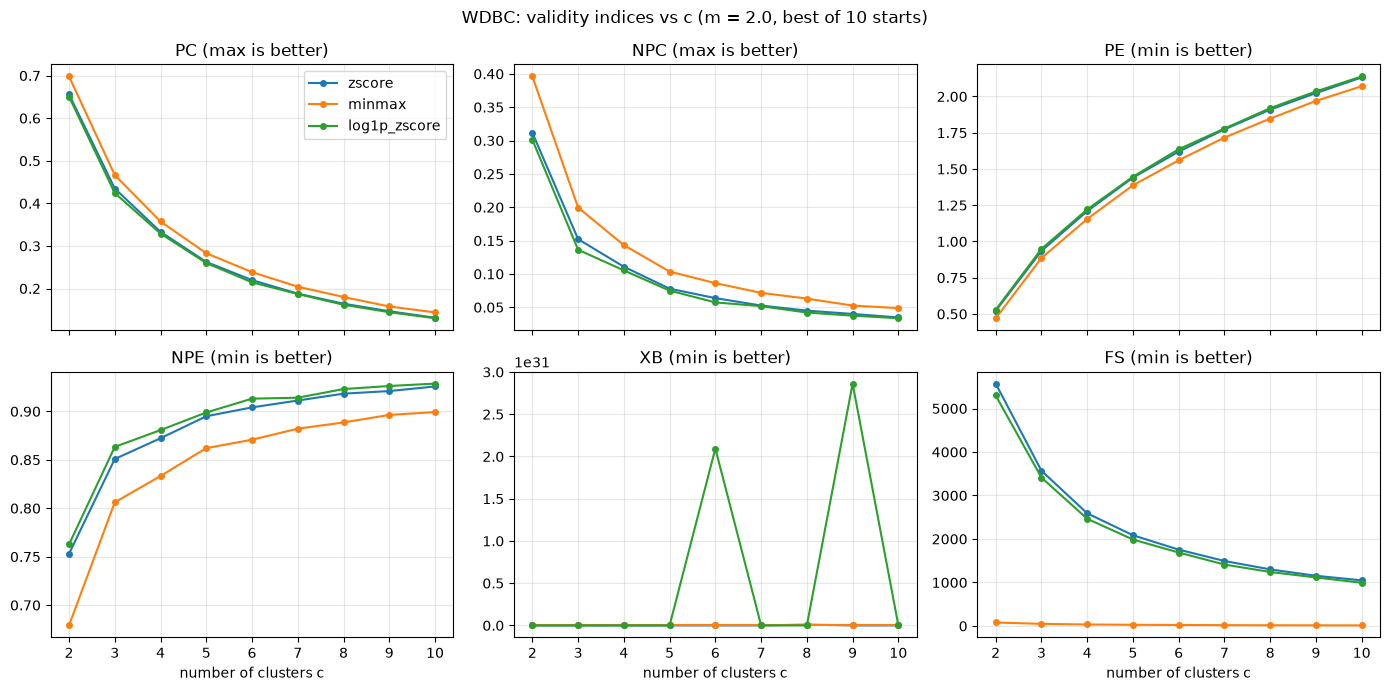

In [16]:
INDICES = {"PC": "max", "NPC": "max", "PE": "min", "NPE": "min", "XB": "min", "FS": "min"}

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for ax, (idx, best_dir) in zip(axes.ravel(), INDICES.items()):
    for name, g in c_sel.groupby("variant", sort=False):
        ax.plot(g["c"], g[idx], marker="o", markersize=4, label=name)
    ax.set_title(f"{idx} ({best_dir} is better)")
    ax.set_xticks(list(C_RANGE))
    ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel("number of clusters c")
axes[0, 0].legend()
fig.suptitle(f"WDBC: validity indices vs c (m = {M_DEFAULT}, best of {N_INIT} starts)")
fig.tight_layout()
fig.savefig(FIG_DIR / "wdbc_c_selection_indices.png", dpi=200)
plt.show()

In [17]:
# c preferred by each index, per variant (argmax for "max" indices, argmin for "min" ones)
pref = {}
for name, g in c_sel.groupby("variant", sort=False):
    g = g.set_index("c")
    pref[name] = {idx: (g[idx].idxmax() if d == "max" else g[idx].idxmin()) for idx, d in INDICES.items()}
pref = pd.DataFrame(pref).T
pref.index.name = "variant"
pref.to_csv(OUT_DIR / "wdbc_c_selection_preferred.csv")
pref

,PC,NPC,PE,NPE,XB,FS
variant,,,,,,
zscore,2,2,2,2,2,10
minmax,2,2,2,2,2,10
log1p_zscore,2,2,2,2,2,10


### 5b: Are the prototypes distinct? (degeneracy check)

For c >= 4, Xie-Beni became extremely large (it divides by the squared distance between the two closest prototypes)
and NPC approached 0. This cell measures directly, for each best run of Step 5:

- `min_proto_dist`: smallest distance between two prototypes
- `n_distinct`: prototypes left after merging those closer than 0.001 x data scale (data scale = sqrt of total variance)
- `dist_to_cog`: mean distance of the prototypes to the centre of gravity of the data, relative to the data scale
- `mean_max_u`: average largest membership of a point (1/c = uniform, 1 = crisp)

Background: Winkler, Klawonn & Kruse (2011), *Fuzzy C-Means in High Dimensional Spaces*, International Journal of
Fuzzy System Applications 1(1), 1-16 (`Papers/winkler2011.pdf`), show that in many dimensions the FCM objective has a
local minimum with the prototypes in the centre of gravity of the data, and that a fuzzifier closer to 1 counteracts this.

In [18]:
diag = pd.DataFrame([
    {"variant": name, "c": c, **fcm.prototype_diagnostics(variants[name], res)}
    for (name, c), res in best_runs.items()
])
diag["1/c"] = 1 / diag["c"]
diag.to_csv(OUT_DIR / "wdbc_c_selection_degeneracy.csv", index=False)
diag.round(4)

,variant,c,min_proto_dist,n_distinct,dist_to_cog,mean_max_u,1/c
0,zscore,2,5.4244,2,0.4956,0.7573,0.5000
1,zscore,3,1.6611,3,0.4498,0.5396,0.3333
2,zscore,4,0.0001,3,0.4893,0.4091,0.2500
3,zscore,5,0.0009,4,0.4824,0.3319,0.2000
4,zscore,6,0.0000,4,0.4782,0.2749,0.1667
5,zscore,7,0.0000,5,0.4948,0.2302,0.1429
6,zscore,8,0.0000,4,0.4756,0.2094,0.1250
7,zscore,9,0.0000,3,0.4935,0.1793,0.1111
8,zscore,10,0.0000,6,0.4874,0.1667,0.1000
9,minmax,2,0.9411,2,0.5965,0.7940,0.5000


## Step 6: Joint study of c and the fuzzifier m

Because the behaviour at m = 2 depends on c, c and m are studied together on a grid:
c = 2 ... 10 and m in `M_GRID`, for all three preprocessing variants, 10 random starts each (best J kept).

`M_GRID` includes the dimension-dependent fuzzifier proposed by Winkler et al. (2011, section "The Effect of the
Fuzzifier"): m = (2 + p) / p, with p = number of features (here p = 30, so m = 1.067).

How to read it: the indices depend on m themselves (smaller m gives crisper partitions, so higher PC and lower PE),
so **for each m, compare the values across c**, not values across m. XB is plotted on a log scale.
This step runs 3 x 9 x 7 x 10 = 1890 FCM runs and may take a few minutes.

In [19]:
p = len(FEATURES)
M_WINKLER = (2 + p) / p
M_GRID = sorted({round(M_WINKLER, 3), 1.1, 1.25, 1.5, 1.75, 2.0, 2.5})
print("M_GRID:", M_GRID)

grid_rows = []
grid_runs = {}                         # (variant, m, c) -> best FCMResult
for name, A in variants.items():
    for m in M_GRID:
        for c in C_RANGE:
            best, info = fcm.fcm_multistart(A, c, m=m, n_init=N_INIT, seed=SEED,
                                            eps=FCM_EPS, max_iter=FCM_MAX_ITER)
            grid_runs[(name, m, c)] = best
            grid_rows.append({
                "variant": name, "m": m, "c": c,
                **fcm.validity_indices(A, best, m),
                **fcm.prototype_diagnostics(A, best),
                "J": best.J, "iterations": best.n_iter,
                "n_at_best": info["n_at_best"], "n_not_converged": info["n_not_converged"],
            })
        g = pd.DataFrame(grid_rows).query("variant == @name and m == @m")
        print(f"{name:12s} m={m:<6} distinct prototypes per c: {g['n_distinct'].tolist()}  "
              f"not converged (of {N_INIT}): {g['n_not_converged'].tolist()}")

grid = pd.DataFrame(grid_rows)
grid.to_csv(OUT_DIR / "wdbc_c_m_grid.csv", index=False)

M_GRID: [1.067, 1.1, 1.25, 1.5, 1.75, 2.0, 2.5]
zscore       m=1.067  distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  not converged (of 10): [0, 0, 0, 0, 0, 0, 0, 0, 0]
zscore       m=1.1    distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  not converged (of 10): [0, 0, 0, 0, 0, 0, 0, 0, 0]
zscore       m=1.25   distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  not converged (of 10): [0, 0, 0, 0, 0, 0, 0, 0, 0]
zscore       m=1.5    distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  not converged (of 10): [0, 0, 0, 0, 0, 0, 0, 0, 0]
zscore       m=1.75   distinct prototypes per c: [2, 3, 4, 5, 5, 7, 7, 8, 7]  not converged (of 10): [0, 0, 0, 0, 0, 8, 1, 10, 9]
zscore       m=2.0    distinct prototypes per c: [2, 3, 3, 4, 4, 5, 4, 3, 6]  not converged (of 10): [0, 0, 0, 2, 0, 10, 0, 0, 10]
zscore       m=2.5    distinct prototypes per c: [2, 2, 3, 3, 2, 3, 2, 2, 4]  not converged (of 10): [0, 0, 0, 9, 0, 0, 0, 0, 10]
minmax       m=1.067  distinct prototypes

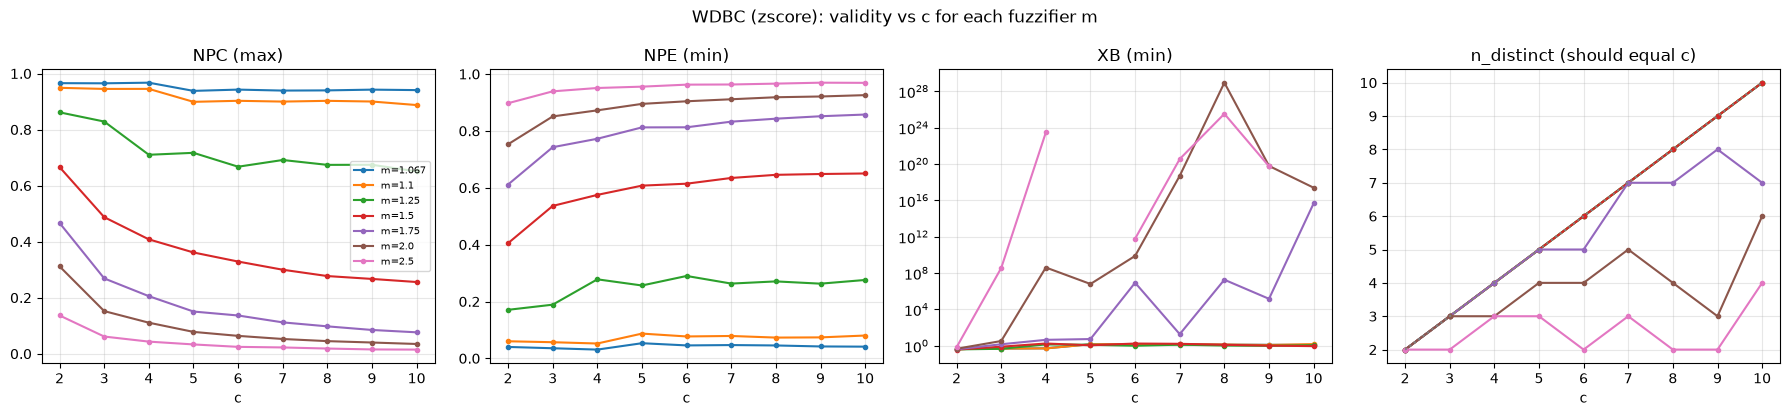

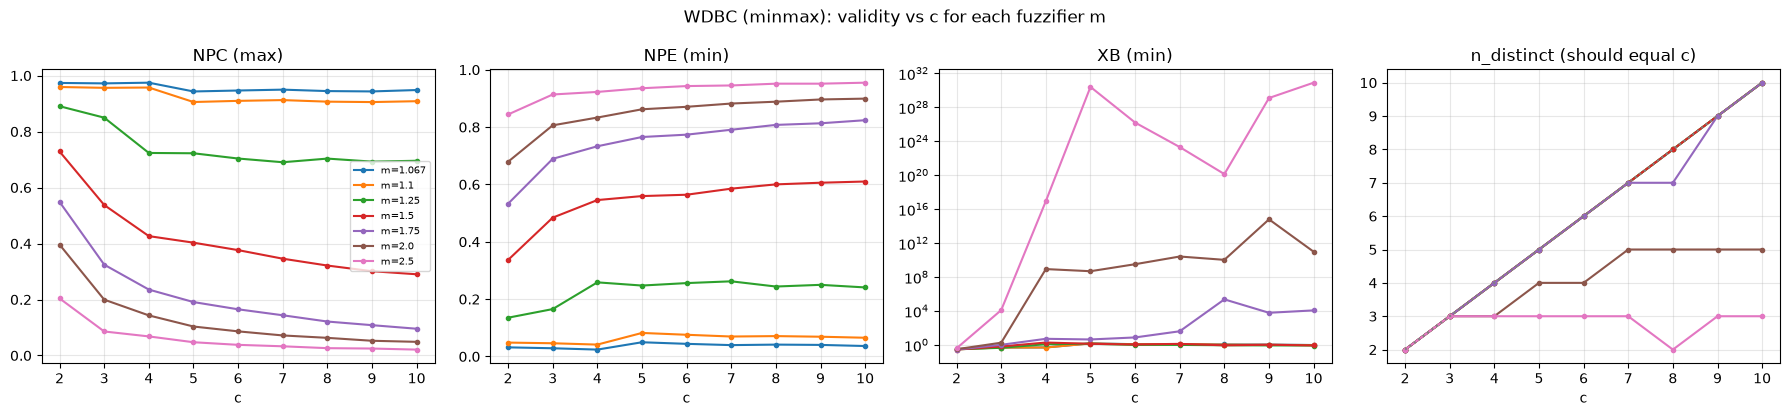

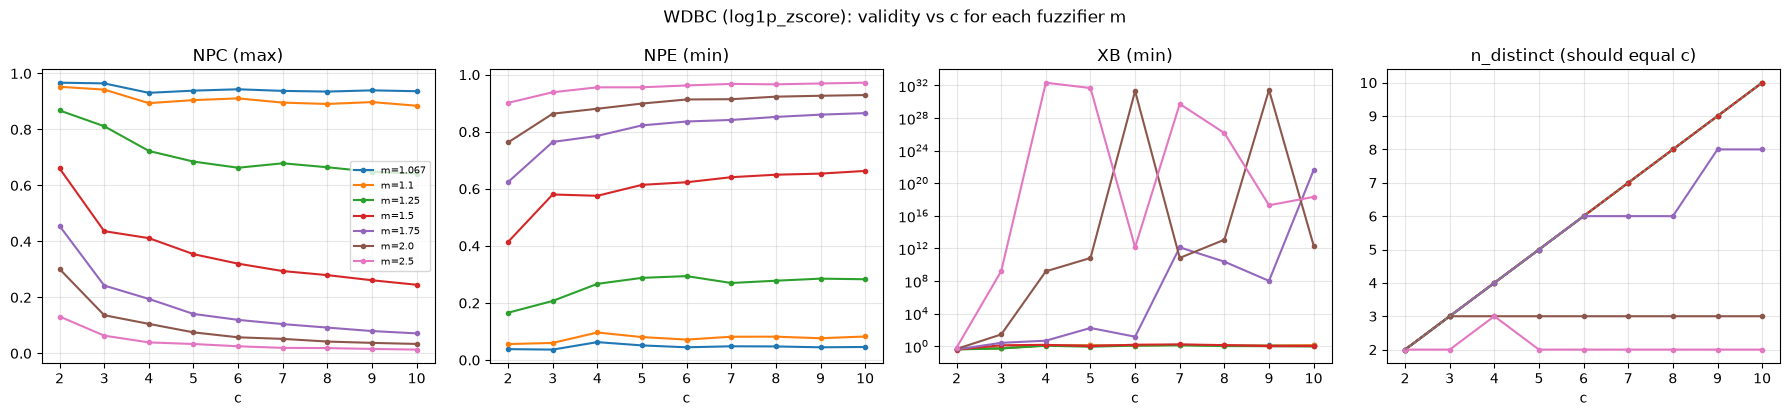

In [20]:
PANELS = [("NPC", "max", False), ("NPE", "min", False), ("XB", "min", True), ("n_distinct", "should equal c", False)]

for name in variants:
    g = grid[grid["variant"] == name]
    fig, axes = plt.subplots(1, len(PANELS), figsize=(18, 4.2), sharex=True)
    for ax, (col, best_dir, logy) in zip(axes, PANELS):
        for m, gm in g.groupby("m"):
            ax.plot(gm["c"], gm[col], marker="o", markersize=3, label=f"m={m}")
        if col == "n_distinct":
            ax.plot(list(C_RANGE), list(C_RANGE), color="grey", linestyle=":", label="= c")
        if logy:
            ax.set_yscale("log")
        ax.set_title(f"{col} ({best_dir})")
        ax.set_xlabel("c")
        ax.set_xticks(list(C_RANGE))
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=7)
    fig.suptitle(f"WDBC ({name}): validity vs c for each fuzzifier m")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"wdbc_c_m_grid_{name}.png", dpi=200)
    plt.show()

In [21]:
# For each (variant, m): the c preferred by each index, considering only non-degenerate partitions
# (all c prototypes distinct). "-" means no valid c for that m.
pref_rows = []
for (name, m), g in grid.groupby(["variant", "m"], sort=False):
    valid = g[g["n_distinct"] == g["c"]].set_index("c")
    row = {"variant": name, "m": m, "valid c": ",".join(map(str, valid.index)) if len(valid) else "-"}
    for idx, d in INDICES.items():
        row[idx] = (valid[idx].idxmax() if d == "max" else valid[idx].idxmin()) if len(valid) else "-"
    pref_rows.append(row)
grid_pref = pd.DataFrame(pref_rows)
grid_pref.to_csv(OUT_DIR / "wdbc_c_m_grid_preferred.csv", index=False)
grid_pref

,variant,m,valid c,PC,NPC,PE,NPE,XB,FS
0,zscore,1.067,"2,3,4,5,6,7,8,9,10",2,4,2,4,2,10
1,zscore,1.100,"2,3,4,5,6,7,8,9,10",2,2,2,4,2,10
2,zscore,1.250,"2,3,4,5,6,7,8,9,10",2,2,2,2,2,10
3,zscore,1.500,"2,3,4,5,6,7,8,9,10",2,2,2,2,2,10
4,zscore,1.750,"2,3,4,5,7",2,2,2,2,2,7
5,zscore,2.000,"2,3",2,2,2,2,2,3
6,zscore,2.500,2,2,2,2,2,2,2
7,minmax,1.067,"2,3,4,5,6,7,8,9,10",2,4,2,4,2,10
8,minmax,1.100,"2,3,4,5,6,7,8,9,10",2,2,2,4,2,10
9,minmax,1.250,"2,3,4,5,6,7,8,9,10",2,2,2,2,2,10


## Step 7: Evaluation against the diagnosis (c = 2)

Decisions (Stefan, 16 Nov): c = 2; two main fuzzifiers, **m = 2** (convention) and **m = 1.5** (largest m in the grid
for which all prototypes stay distinct for every c); sensitivity over all m in `M_GRID`; plus a look at c = 4 at m = (2+p)/p.

The diagnosis is used **only from here on**, and only to evaluate. Helpers are in `src/evaluation.py`:
contingency table, ARI, NMI, accuracy after the best cluster -> class mapping, and recall per class
(recall_M = share of malignant cases put in the "malignant" cluster).

Requires `pip install scikit-learn` (ARI, NMI, k-means baseline, train/test split).

In [22]:
import evaluation
importlib.reload(evaluation)

C_MAIN = 2
M_MAIN = [2.0, 1.5]

rows, tables = [], {}
for m in M_MAIN:
    for name in variants:
        res = grid_runs[(name, m, C_MAIN)]
        scores, mapping = evaluation.external_scores(y, res.labels)
        rows.append({"variant": name, "m": m, **scores,
                     "NPC": fcm.normalized_partition_coefficient(res.U), "mapping": mapping})
        tables[(name, m)] = evaluation.contingency(y, res.labels).rename(index=mapping)

main_eval = pd.DataFrame(rows)
main_eval.to_csv(OUT_DIR / "wdbc_eval_main.csv", index=False)

for (name, m), tab in tables.items():
    tab.to_csv(OUT_DIR / f"wdbc_contingency_{name}_m{m}.csv")
    print(f"--- {name}, m = {m}  (rows: cluster named after its mapped class)")
    print(tab, "\n")

main_eval.drop(columns="mapping").round(4)

--- zscore, m = 2.0  (rows: cluster named after its mapped class)
class      B    M
cluster          
M         18  181
B        339   31 

--- minmax, m = 2.0  (rows: cluster named after its mapped class)
class      B    M
cluster          
B        344   28
M         13  184 

--- log1p_zscore, m = 2.0  (rows: cluster named after its mapped class)
class      B    M
cluster          
M         20  191
B        337   21 

--- zscore, m = 1.5  (rows: cluster named after its mapped class)
class      B    M
cluster          
M         13  177
B        344   35 

--- minmax, m = 1.5  (rows: cluster named after its mapped class)
class      B    M
cluster          
M          9  180
B        348   32 

--- log1p_zscore, m = 1.5  (rows: cluster named after its mapped class)
class      B    M
cluster          
B        343   27
M         14  185 



,variant,m,ARI,NMI,accuracy,recall_B,recall_M,NPC
0,zscore,2.0,0.6829,0.5612,0.9139,0.9496,0.8538,0.3118
1,minmax,2.0,0.7305,0.6152,0.9279,0.9636,0.8679,0.3961
2,log1p_zscore,2.0,0.7310,0.6117,0.9279,0.9440,0.9009,0.3014
3,zscore,1.5,0.6883,0.5733,0.9156,0.9636,0.8349,0.6661
4,minmax,1.5,0.7302,0.6231,0.9279,0.9748,0.8491,0.7289
5,log1p_zscore,1.5,0.7306,0.6140,0.9279,0.9608,0.8726,0.6609


### 7a: Sensitivity to m (c = 2)

For every m in the grid: agreement with the diagnosis, how fuzzy the partition is (NPC), and how much the hard
partition differs from the one at m = 2 (`ARI_vs_m2`, 1 = same hard assignment).

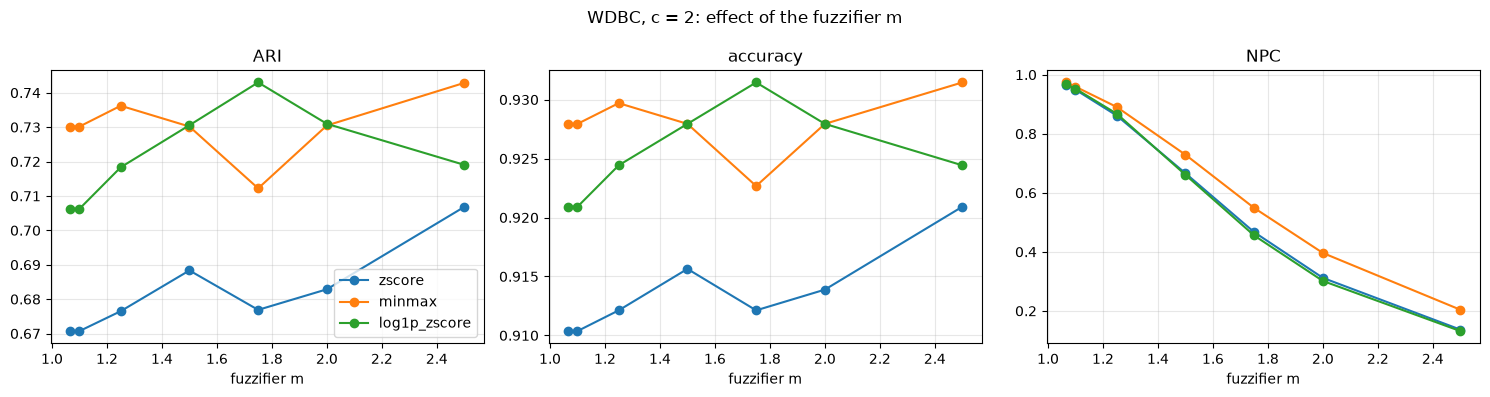

,variant,m,ARI,NMI,accuracy,recall_B,recall_M,NPC,mean_max_u,ARI_vs_m2
0,zscore,1.067,0.6707,0.5546,0.9104,0.9608,0.8255,0.9657,0.9879,0.9301
1,zscore,1.100,0.6707,0.5546,0.9104,0.9608,0.8255,0.9491,0.9820,0.9301
2,zscore,1.250,0.6765,0.5620,0.9121,0.9636,0.8255,0.8616,0.9528,0.9233
3,zscore,1.500,0.6883,0.5733,0.9156,0.9636,0.8349,0.6661,0.8893,0.9370
4,zscore,1.750,0.6769,0.5562,0.9121,0.9524,0.8443,0.4667,0.8196,0.9788
5,zscore,2.000,0.6829,0.5612,0.9139,0.9496,0.8538,0.3118,0.7573,1.0000
6,zscore,2.500,0.7068,0.5851,0.9209,0.9440,0.8821,0.1366,0.6671,0.9441
7,minmax,1.067,0.7302,0.6231,0.9279,0.9748,0.8491,0.9738,0.9914,0.9439
8,minmax,1.100,0.7302,0.6231,0.9279,0.9748,0.8491,0.9593,0.9863,0.9439
9,minmax,1.250,0.7362,0.6319,0.9297,0.9776,0.8491,0.8906,0.9629,0.9370


In [23]:
sens_rows = []
for name in variants:
    ref = grid_runs[(name, 2.0, C_MAIN)].labels
    for m in M_GRID:
        res = grid_runs[(name, m, C_MAIN)]
        scores, _ = evaluation.external_scores(y, res.labels)
        sens_rows.append({"variant": name, "m": m, **scores,
                          "NPC": fcm.normalized_partition_coefficient(res.U),
                          "mean_max_u": res.U.max(axis=0).mean(),
                          "ARI_vs_m2": evaluation.adjusted_rand_score(ref, res.labels)})
m_sens = pd.DataFrame(sens_rows)
m_sens.to_csv(OUT_DIR / "wdbc_m_sensitivity_c2.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["ARI", "accuracy", "NPC"]):
    for name, g in m_sens.groupby("variant", sort=False):
        ax.plot(g["m"], g[col], marker="o", label=name)
    ax.set_xlabel("fuzzifier m")
    ax.set_title(col)
    ax.grid(alpha=0.3)
axes[0].legend()
fig.suptitle("WDBC, c = 2: effect of the fuzzifier m")
fig.tight_layout()
fig.savefig(FIG_DIR / "wdbc_m_sensitivity_c2.png", dpi=200)
plt.show()
m_sens.round(4)

### 7b: Fuzzy view: memberships of benign and malignant cases

For each main configuration, the membership in the cluster mapped to "M", split by the true diagnosis.
Misassigned points are split into *uncertain* (largest membership < 0.6) and *confident* (largest membership >= 0.8).

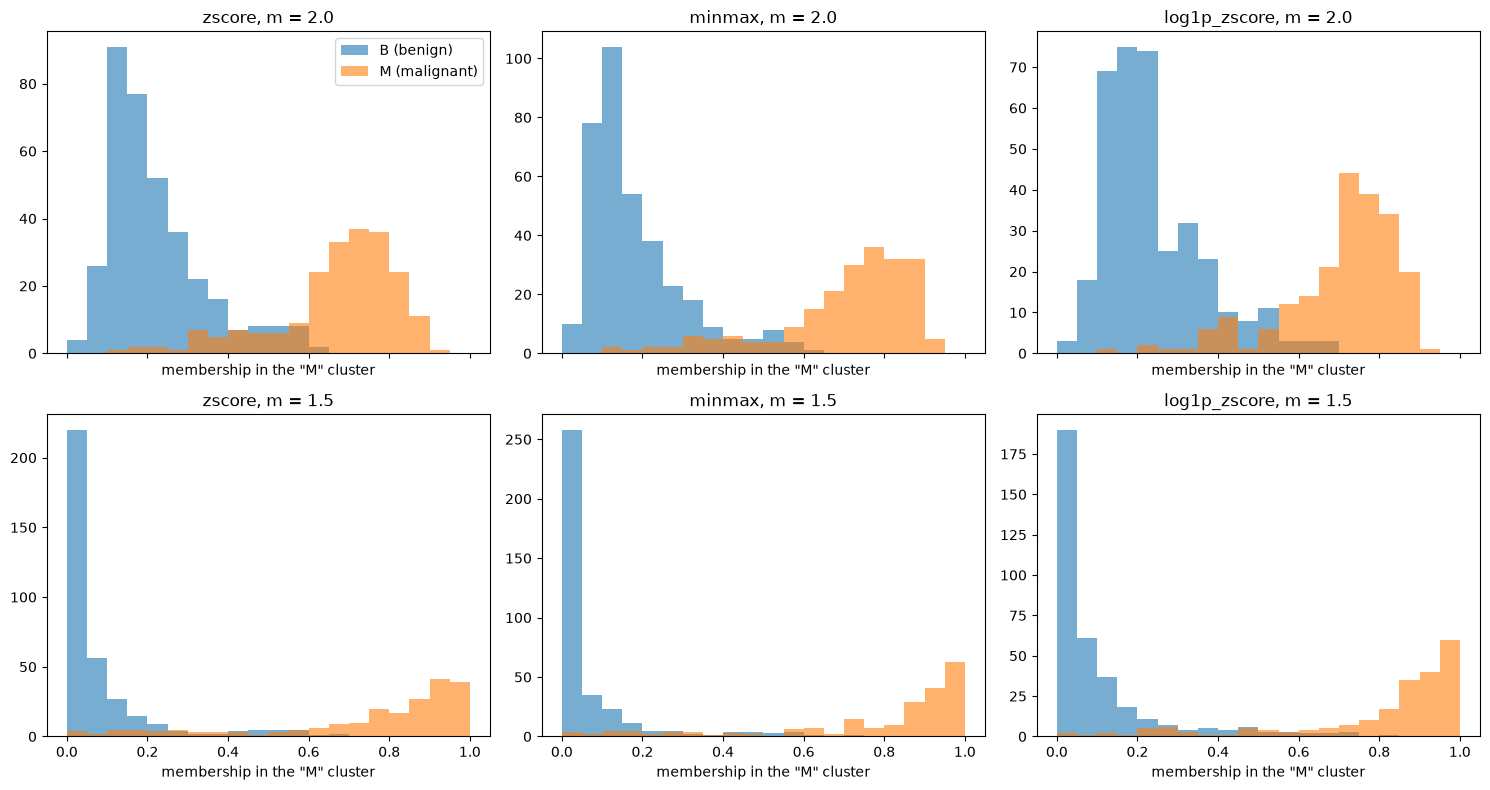

,variant,m,misassigned,uncertain (<0.6),confident (>=0.8)
0,zscore,2.0,49,29,3
1,minmax,2.0,41,22,3
2,log1p_zscore,2.0,41,24,1
3,zscore,1.5,48,14,16
4,minmax,1.5,41,12,16
5,log1p_zscore,1.5,41,12,7


In [24]:
fig, axes = plt.subplots(len(M_MAIN), len(variants), figsize=(15, 4 * len(M_MAIN)), sharex=True, squeeze=False)
mis_rows = []
for i, m in enumerate(M_MAIN):
    for j, name in enumerate(variants):
        res = grid_runs[(name, m, C_MAIN)]
        _, mapping = evaluation.external_scores(y, res.labels)
        k_M = [k for k, cl in mapping.items() if cl == "M"][0]
        u_M = res.U[k_M]
        ax = axes[i, j]
        bins = np.linspace(0, 1, 21)
        ax.hist(u_M[y == "B"], bins=bins, alpha=0.6, label="B (benign)")
        ax.hist(u_M[y == "M"], bins=bins, alpha=0.6, label="M (malignant)")
        ax.set_title(f"{name}, m = {m}")
        ax.set_xlabel('membership in the "M" cluster')
        pred = np.array([mapping[l] for l in res.labels])
        wrong = pred != y
        umax = res.U.max(axis=0)
        mis_rows.append({"variant": name, "m": m, "misassigned": int(wrong.sum()),
                         "uncertain (<0.6)": int((wrong & (umax < 0.6)).sum()),
                         "confident (>=0.8)": int((wrong & (umax >= 0.8)).sum())})
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "wdbc_membership_by_diagnosis.png", dpi=200)
plt.show()
misassigned = pd.DataFrame(mis_rows)
misassigned.to_csv(OUT_DIR / "wdbc_misassigned.csv", index=False)
misassigned

### 7c: Picture of the main result (PCA projection, for display only)

FCM ran on all 30 features; the points are only *drawn* on the first two principal components of the z-score data.
Colour = membership in the "M" cluster (z-score, m = 2), marker = true diagnosis.

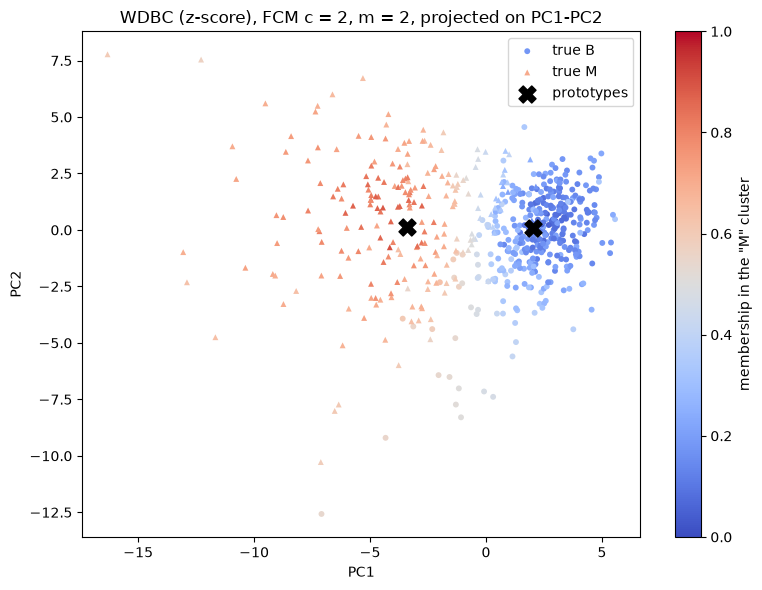

In [25]:
Az = variants["zscore"]
_, _, Vt = np.linalg.svd(Az - Az.mean(axis=0), full_matrices=False)
P = (Az - Az.mean(axis=0)) @ Vt[:2].T

res = grid_runs[("zscore", 2.0, C_MAIN)]
_, mapping = evaluation.external_scores(y, res.labels)
k_M = [k for k, cl in mapping.items() if cl == "M"][0]
proto_P = (res.V - Az.mean(axis=0)) @ Vt[:2].T

fig, ax = plt.subplots(figsize=(8, 6))
for diag, marker in (("B", "o"), ("M", "^")):
    sel = y == diag
    sc = ax.scatter(P[sel, 0], P[sel, 1], c=res.U[k_M, sel], cmap="coolwarm", vmin=0, vmax=1,
                    marker=marker, s=18, edgecolors="none", label=f"true {diag}")
ax.scatter(proto_P[:, 0], proto_P[:, 1], c="black", marker="X", s=150, label="prototypes")
fig.colorbar(sc, ax=ax, label='membership in the "M" cluster')
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("WDBC (z-score), FCM c = 2, m = 2, projected on PC1-PC2")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "wdbc_fcm_pca_projection.png", dpi=200)
plt.show()

### 7d: Baseline: hard k-means

k-means (scikit-learn, k = 2, 10 starts, same seed) on the same three preprocessing variants: does the fuzzy method
agree with the diagnosis better or worse than its hard counterpart? Also: how similar are the k-means and FCM partitions.

In [26]:
from sklearn.cluster import KMeans

km_rows = []
for name, A in variants.items():
    km = KMeans(n_clusters=C_MAIN, n_init=N_INIT, random_state=SEED).fit(A)
    scores, _ = evaluation.external_scores(y, km.labels_)
    km_rows.append({"method": "k-means", "variant": name, "m": None, **scores})
    for m in M_MAIN:
        res = grid_runs[(name, m, C_MAIN)]
        fscores, _ = evaluation.external_scores(y, res.labels)
        km_rows.append({"method": "FCM", "variant": name, "m": m, **fscores,
                        "ARI_vs_kmeans": evaluation.adjusted_rand_score(km.labels_, res.labels)})
baseline = pd.DataFrame(km_rows)
baseline.to_csv(OUT_DIR / "wdbc_kmeans_baseline.csv", index=False)
baseline.round(4)

,method,variant,m,ARI,NMI,accuracy,recall_B,recall_M,ARI_vs_kmeans
0,k-means,zscore,NaN,0.6536,0.5324,0.9051,0.9496,0.8302,NaN
1,FCM,zscore,2.0,0.6829,0.5612,0.9139,0.9496,0.8538,0.9648
2,FCM,zscore,1.5,0.6883,0.5733,0.9156,0.9636,0.8349,0.9577
3,k-means,minmax,NaN,0.7302,0.6231,0.9279,0.9748,0.8491,NaN
4,FCM,minmax,2.0,0.7305,0.6152,0.9279,0.9636,0.8679,0.9439
5,FCM,minmax,1.5,0.7302,0.6231,0.9279,0.9748,0.8491,1.0000
6,k-means,log1p_zscore,NaN,0.7063,0.5908,0.9209,0.9636,0.8491,NaN
7,FCM,log1p_zscore,2.0,0.7310,0.6117,0.9279,0.9440,0.9009,0.8764
8,FCM,log1p_zscore,1.5,0.7306,0.6140,0.9279,0.9608,0.8726,0.9578


### 7e: Do the clusters carry over to unseen cases? (70/30 check)

The data is split 70/30 (stratified by diagnosis only so both parts keep the class proportions; FCM never sees the labels).
**All preprocessing parameters (means, std, min, max) are computed on the 70% only** and then applied to the 30%,
otherwise information from the test part would leak into the preprocessing.
FCM runs on the 70%; the 30% are assigned to the learned prototypes with the FCM membership formula.
The cluster -> class mapping is learned on the 70% and reused unchanged for the 30%.
This is not a classifier: it only checks whether the structure found generalises.

In [27]:
from sklearn.model_selection import train_test_split

def preprocess_fit_apply(name, A_train, A_test):
    """Fit the preprocessing on the training part only, then apply it to both parts."""
    if name == "log1p_zscore":
        A_train, A_test, name = np.log1p(A_train), np.log1p(A_test), "zscore"
    if name == "zscore":
        mu, sd = A_train.mean(axis=0), A_train.std(axis=0)
        return (A_train - mu) / sd, (A_test - mu) / sd
    if name == "minmax":
        lo, hi = A_train.min(axis=0), A_train.max(axis=0)
        return (A_train - lo) / (hi - lo), (A_test - lo) / (hi - lo)
    raise ValueError(name)

idx_train, idx_test = train_test_split(np.arange(len(y)), test_size=0.3, stratify=y, random_state=SEED)
print("train:", len(idx_train), "test:", len(idx_test))

split_rows = []
for name in variants:
    A_tr, A_te = preprocess_fit_apply(name, X_raw[idx_train], X_raw[idx_test])
    for m in M_MAIN:
        res, _ = fcm.fcm_multistart(A_tr, C_MAIN, m=m, n_init=N_INIT, seed=SEED, eps=FCM_EPS, max_iter=FCM_MAX_ITER)
        tr_scores, mapping = evaluation.external_scores(y[idx_train], res.labels)
        U_te = fcm.memberships(fcm.squared_distances(A_te, res.V), m)
        te_scores, _ = evaluation.external_scores(y[idx_test], U_te.argmax(axis=0), mapping=mapping)
        split_rows.append({"variant": name, "m": m,
                           **{f"train_{k}": v for k, v in tr_scores.items()},
                           **{f"test_{k}": v for k, v in te_scores.items()}})
split_eval = pd.DataFrame(split_rows)
split_eval.to_csv(OUT_DIR / "wdbc_split_70_30.csv", index=False)
split_eval.round(4)

train: 398 test: 171


,variant,m,train_ARI,train_NMI,train_accuracy,train_recall_B,train_recall_M,test_ARI,test_NMI,test_accuracy,test_recall_B,test_recall_M
0,zscore,2.0,0.6684,0.5446,0.9095,0.940,0.8581,0.7156,0.6077,0.9240,0.9720,0.8438
1,zscore,1.5,0.6763,0.5572,0.9121,0.956,0.8378,0.7154,0.6178,0.9240,0.9813,0.8281
2,minmax,2.0,0.7191,0.5992,0.9246,0.952,0.8784,0.7770,0.6915,0.9415,0.9907,0.8594
3,minmax,1.5,0.7272,0.6176,0.9271,0.972,0.8514,0.7561,0.6713,0.9357,0.9907,0.8438
4,log1p_zscore,2.0,0.7194,0.5991,0.9246,0.940,0.8986,0.7776,0.6665,0.9415,0.9626,0.9062
5,log1p_zscore,1.5,0.7106,0.5895,0.9221,0.948,0.8784,0.8195,0.7347,0.9532,0.9907,0.8906


### 7f: A closer look at c = 4 (m = (2+p)/p)

At the near-crisp fuzzifier, NPC and NPE preferred c = 4 (Step 6). What are these four clusters?
Contingency with the diagnosis for each variant, and the prototypes of the z-score run in z-units
(how many standard deviations each cluster centre lies above/below the mean, per feature).

--- zscore, c = 4, m = 1.067: ARI=0.552  NMI=0.462  purity=0.895
class      B   M
cluster         
0        321  24
1          0  37
2         36  54
3          0  97 

--- minmax, c = 4, m = 1.067: ARI=0.607  NMI=0.503  purity=0.919
class      B   M
cluster         
0        332  21
1          0  96
2         25  57
3          0  38 

--- log1p_zscore, c = 4, m = 1.067: ARI=0.336  NMI=0.412  purity=0.907
class      B    M
cluster          
0        198   33
1          0  118
2        140    1
3         19   60 



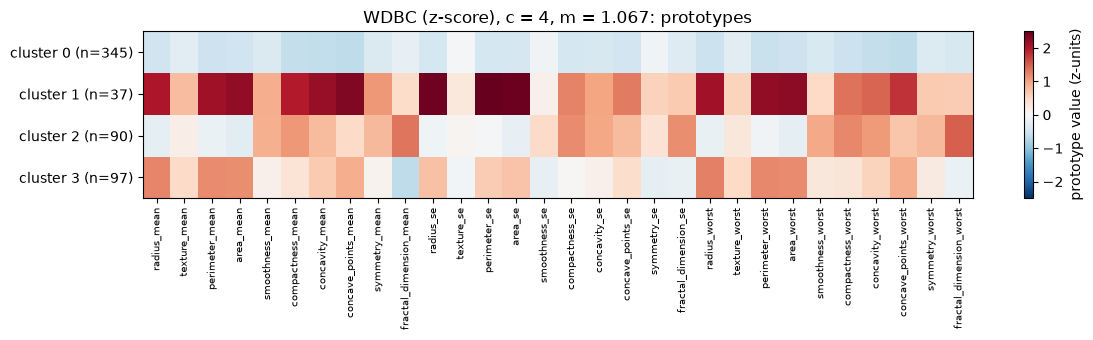

In [28]:
m_w = round(M_WINKLER, 3)
for name in variants:
    res4 = grid_runs[(name, m_w, 4)]
    tab4 = evaluation.contingency(y, res4.labels)
    tab4.to_csv(OUT_DIR / f"wdbc_contingency_c4_{name}.csv")
    scores4, _ = evaluation.external_scores(y, res4.labels)
    print(f"--- {name}, c = 4, m = {m_w}: ARI={scores4['ARI']:.3f}  NMI={scores4['NMI']:.3f}  "
          f"purity={scores4['accuracy']:.3f}")
    print(tab4, "\n")

res4 = grid_runs[("zscore", m_w, 4)]
fig, ax = plt.subplots(figsize=(12, 3.5))
im = ax.imshow(res4.V, cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=7)
sizes = np.bincount(res4.labels, minlength=4)
ax.set_yticks(range(4), [f"cluster {k} (n={sizes[k]})" for k in range(4)])
fig.colorbar(im, ax=ax, label="prototype value (z-units)")
ax.set_title(f"WDBC (z-score), c = 4, m = {m_w}: prototypes")
fig.tight_layout()
fig.savefig(FIG_DIR / "wdbc_c4_prototypes.png", dpi=200)
plt.show()

### 7g: Repeated 70/30 splits

The single split of 7e is repeated `N_SPLITS` = 10 times with different random splits (seeds `SEED`, `SEED + 1`, ...),
same procedure (preprocessing fitted on the training part only, mapping learned on the training part).
Reported: mean and standard deviation over the splits, and the test - train difference per split
(if the structure generalises, the difference should be centred near 0).

In [29]:
N_SPLITS = 10

rep_rows = []
for s in range(N_SPLITS):
    idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.3, stratify=y, random_state=SEED + s)
    for name in variants:
        A_tr, A_te = preprocess_fit_apply(name, X_raw[idx_tr], X_raw[idx_te])
        for m in M_MAIN:
            res, _ = fcm.fcm_multistart(A_tr, C_MAIN, m=m, n_init=N_INIT, seed=SEED,
                                        eps=FCM_EPS, max_iter=FCM_MAX_ITER)
            tr, mapping = evaluation.external_scores(y[idx_tr], res.labels)
            U_te = fcm.memberships(fcm.squared_distances(A_te, res.V), m)
            te, _ = evaluation.external_scores(y[idx_te], U_te.argmax(axis=0), mapping=mapping)
            rep_rows.append({"split": s, "variant": name, "m": m,
                             **{f"train_{k}": v for k, v in tr.items()},
                             **{f"test_{k}": v for k, v in te.items()}})
rep = pd.DataFrame(rep_rows)
for k in ("ARI", "accuracy", "recall_M"):
    rep[f"diff_{k}"] = rep[f"test_{k}"] - rep[f"train_{k}"]
rep.to_csv(OUT_DIR / "wdbc_split_70_30_repeated.csv", index=False)

cols = ["train_ARI", "test_ARI", "diff_ARI", "train_accuracy", "test_accuracy", "test_recall_M", "diff_recall_M"]
rep_summary = rep.groupby(["variant", "m"], sort=False)[cols].agg(["mean", "std"])
rep_summary.to_csv(OUT_DIR / "wdbc_split_70_30_repeated_summary.csv")
rep_summary.round(4)

train_ARI         test_ARI         diff_ARI          \
                      mean     std     mean     std     mean     std   
variant      m                                                         
zscore       2.0    0.6920  0.0276   0.6932  0.0612   0.0012  0.0870   
             1.5    0.6866  0.0301   0.6770  0.0554  -0.0096  0.0797   
minmax       2.0    0.7279  0.0342   0.7399  0.0778   0.0121  0.0998   
             1.5    0.7249  0.0293   0.7250  0.0680   0.0000  0.0828   
log1p_zscore 2.0    0.7265  0.0277   0.7351  0.0484   0.0086  0.0732   
             1.5    0.7367  0.0327   0.7458  0.0710   0.0091  0.0991   

                 train_accuracy         test_accuracy         test_recall_M  \
                           mean     std          mean     std          mean   
variant      m                                                                
zscore       2.0         0.9166  0.0081        0.9170  0.0185        0.8531   
             1.5         0.9151  0.0089        0.9123  0.0168        0.8281   
minmax       2.0         0.9271  0.0100        0.9304  0.0226        0.8688   
             1.5         0.9264  0.0085        0.9263  0.0197        0.8422   
log1p_zscore 2.0         0.9266  0.0081        0.9292  0.0139        0.8984   
             1.5         0.9296  0.0094        0.9322  0.0203        0.8797   

                         diff_recall_M          
                     std          mean     std  
variant      m                                  
zscore       2.0  0.0527       -0.0090  0.0728  
             1.5  0.0477       -0.0111  0.0692  
minmax       2.0  0.0501        0.0005  0.0697  
             1.5  0.0439       -0.0098  0.0625  
log1p_zscore 2.0  0.0418       -0.0029  0.0593  
             1.5  0.0466       -0.0021  0.0690

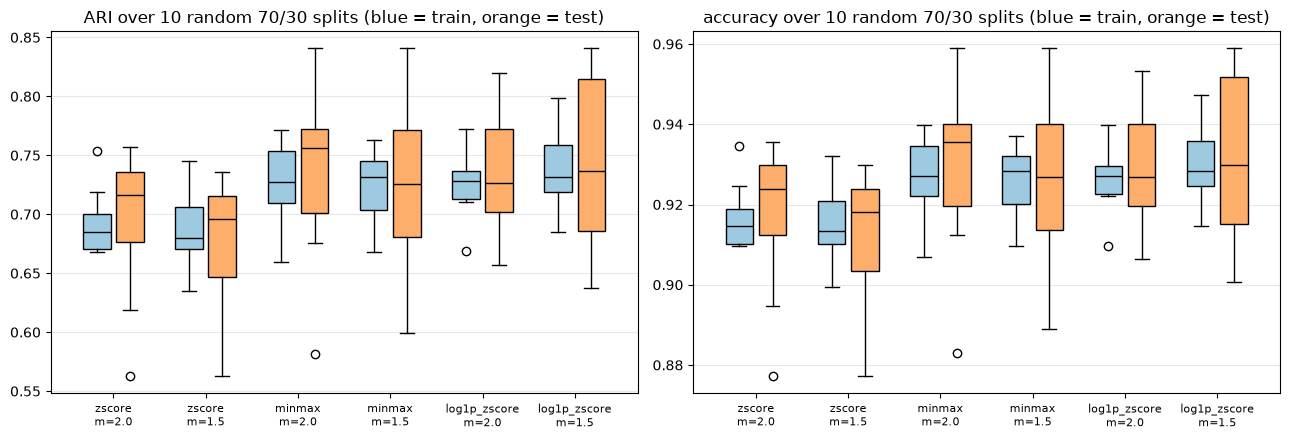

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)
groups = list(rep.groupby(["variant", "m"], sort=False))
labels = [f"{n}\nm={m}" for (n, m), _ in groups]
for ax, k in zip(axes, ["ARI", "accuracy"]):
    data_tr = [g[f"train_{k}"].to_numpy() for _, g in groups]
    data_te = [g[f"test_{k}"].to_numpy() for _, g in groups]
    pos = np.arange(len(groups))
    ax.boxplot(data_tr, positions=pos - 0.18, widths=0.3, patch_artist=True,
               boxprops={"facecolor": "#9ecae1"}, medianprops={"color": "black"})
    ax.boxplot(data_te, positions=pos + 0.18, widths=0.3, patch_artist=True,
               boxprops={"facecolor": "#fdae6b"}, medianprops={"color": "black"})
    ax.set_xticks(pos, labels, fontsize=8)
    ax.set_title(f"{k} over {N_SPLITS} random 70/30 splits (blue = train, orange = test)")
    ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(FIG_DIR / "wdbc_split_70_30_repeated.png", dpi=200)
plt.show()

### 7h: Extension: possibilistic c-means (PCM) started from FCM

FCM memberships sum to 1 over the clusters, so they express *sharing* between clusters, not *typicality*:
a point far from both prototypes still gets memberships that sum to 1 (and drift towards 0.5).
PCM (Krishnapuram & Keller 1993; *The Possibilistic C-Means Algorithm: Insights and Recommendations*,
IEEE Trans. Fuzzy Systems 4(3), 1996, `Papers/krishnapuram1996.pdf`) drops that constraint.

Recipe from lecture 05a, slides 21-23: (1) run FCM, (2) compute eta_i from the FCM result, (3) run PCM from the FCM prototypes.
Configuration: z-score, c = 2, m = 2 (the main FCM run). Checked:
- do the two PCM prototypes stay apart, or become coincident (the known PCM weakness)?
- how do PCM typicalities compare with FCM memberships, especially for extreme and misassigned points?
- the hard assignment (largest typicality) against the diagnosis.

This is an extension that probes a limitation of FCM; the method of the report remains FCM.

In [31]:
name_h, m_h = "zscore", 2.0
A_h = variants[name_h]
res_f = grid_runs[(name_h, m_h, C_MAIN)]

eta = fcm.pcm_eta(A_h, res_f.U, res_f.V, m_h)
res_p = fcm.pcm(A_h, res_f.V, eta, m=m_h, eps=FCM_EPS, max_iter=FCM_MAX_ITER)

f_scores, f_map = evaluation.external_scores(y, res_f.labels)
p_scores, p_map = evaluation.external_scores(y, res_p.labels)

d_f = fcm.prototype_diagnostics(A_h, res_f)
d_p = fcm.prototype_diagnostics(A_h, res_p)
pcm_summary = pd.DataFrame({
    "FCM": {"iterations": res_f.n_iter, "converged": res_f.converged,
            "prototype distance": d_f["min_proto_dist"], **f_scores},
    "PCM": {"iterations": res_p.n_iter, "converged": res_p.converged,
            "prototype distance": d_p["min_proto_dist"], **p_scores},
})
print("eta per cluster:", {f_map[k]: round(float(e), 3) for k, e in enumerate(eta)})
print("cluster mapping FCM:", f_map, " PCM:", p_map)
print("ARI between FCM and PCM hard labels:", round(evaluation.adjusted_rand_score(res_f.labels, res_p.labels), 4))
pcm_summary.to_csv(OUT_DIR / "wdbc_pcm_vs_fcm.csv")
pcm_summary

eta per cluster: {'M': 31.683, 'B': 16.506}
cluster mapping FCM: {0: 'M', 1: 'B'}  PCM: {0: 'B'}
ARI between FCM and PCM hard labels: 0.0


,FCM,PCM
iterations,26,15
converged,True,True
prototype distance,5.424365,0.355117
ARI,0.682865,0.0
NMI,0.561214,0.0
accuracy,0.913884,0.627417
recall_B,0.94958,1.0
recall_M,0.853774,0.0


In [32]:
# Point-level comparison: largest FCM membership vs largest PCM typicality
pts = pd.DataFrame({
    "diagnosis": y,
    "fcm_max_u": res_f.U.max(axis=0),
    "pcm_max_t": res_p.U.max(axis=0),
    "pcm_sum_t": res_p.U.sum(axis=0),
    "dist_to_nearest_proto": np.sqrt(fcm.squared_distances(A_h, res_p.V).min(axis=0)),
    "fcm_correct": np.array([f_map[l] for l in res_f.labels]) == y,
})
pts.to_csv(OUT_DIR / "wdbc_pcm_points.csv", index_label="row")

print("points atypical of both clusters (largest typicality < 0.5):",
      int((pts["pcm_max_t"] < 0.5).sum()), "of", len(pts))
print(pts.groupby("diagnosis")["pcm_max_t"].describe().round(3))
print("\nmisassigned by FCM: mean largest FCM membership =",
      round(pts.loc[~pts.fcm_correct, "fcm_max_u"].mean(), 3),
      " mean largest PCM typicality =", round(pts.loc[~pts.fcm_correct, "pcm_max_t"].mean(), 3))
print("\n10 most atypical points:")
pts.sort_values("pcm_max_t").head(10).round(3)

points atypical of both clusters (largest typicality < 0.5): 171 of 569
           count   mean    std    min    25%    50%    75%    max
diagnosis                                                        
B          357.0  0.708  0.154  0.071  0.636  0.747  0.815  0.966
M          212.0  0.458  0.186  0.063  0.321  0.447  0.592  0.867

misassigned by FCM: mean largest FCM membership = 0.607  mean largest PCM typicality = 0.6

10 most atypical points:


,diagnosis,fcm_max_u,pcm_max_t,pcm_sum_t,dist_to_nearest_proto,fcm_correct
461,M,0.601,0.063,0.097,21.644,True
212,M,0.574,0.066,0.101,21.114,True
152,B,0.541,0.071,0.109,20.301,False
122,M,0.636,0.099,0.151,16.971,True
78,M,0.643,0.113,0.174,15.745,True
3,M,0.588,0.125,0.193,14.862,True
108,M,0.693,0.126,0.193,14.839,True
68,B,0.550,0.140,0.217,13.942,False
352,M,0.703,0.153,0.235,13.247,True
190,M,0.606,0.157,0.243,13.040,True


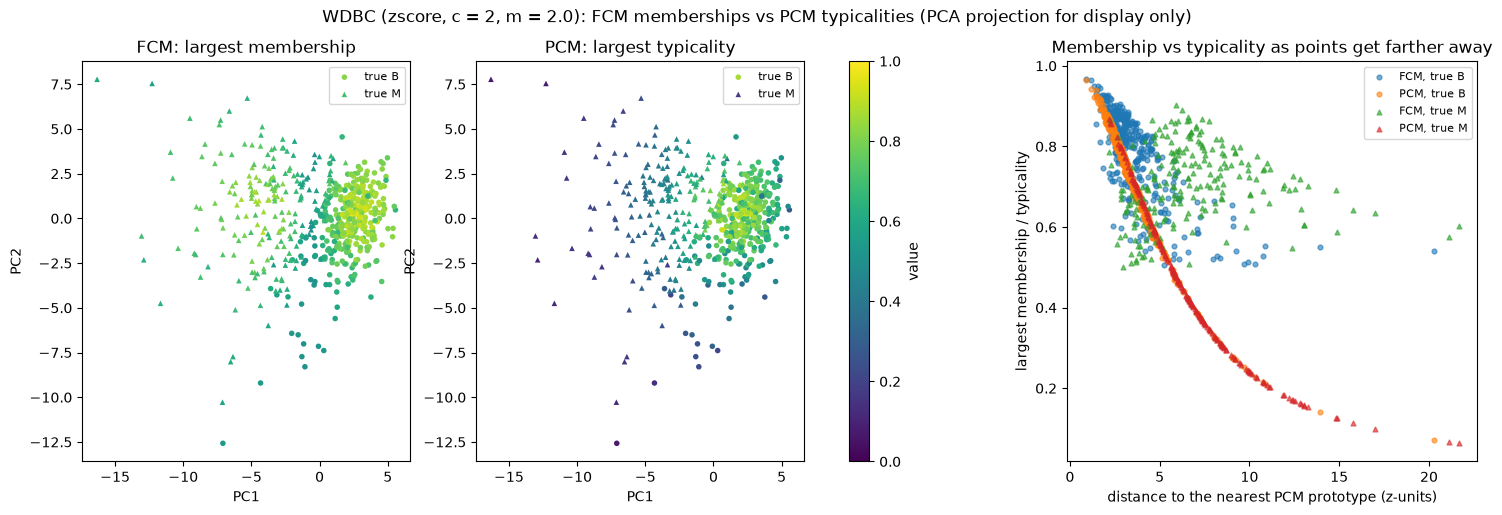

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for ax, (vals, title) in zip(axes[:2], [(pts["fcm_max_u"], "FCM: largest membership"),
                                        (pts["pcm_max_t"], "PCM: largest typicality")]):
    for diag, marker in (("B", "o"), ("M", "^")):
        sel = y == diag
        sc = ax.scatter(P[sel, 0], P[sel, 1], c=vals[sel], cmap="viridis", vmin=0, vmax=1,
                        marker=marker, s=16, edgecolors="none", label=f"true {diag}")
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(fontsize=8)
fig.colorbar(sc, ax=axes[:2], label="value")

ax = axes[2]
for diag, marker in (("B", "o"), ("M", "^")):
    sel = y == diag
    ax.scatter(pts.loc[sel, "dist_to_nearest_proto"], pts.loc[sel, "fcm_max_u"], marker=marker, s=12,
               alpha=0.6, label=f"FCM, true {diag}")
    ax.scatter(pts.loc[sel, "dist_to_nearest_proto"], pts.loc[sel, "pcm_max_t"], marker=marker, s=12,
               alpha=0.6, label=f"PCM, true {diag}")
ax.set_xlabel("distance to the nearest PCM prototype (z-units)")
ax.set_ylabel("largest membership / typicality")
ax.set_title("Membership vs typicality as points get farther away")
ax.legend(fontsize=8)
fig.suptitle(f"WDBC ({name_h}, c = {C_MAIN}, m = {m_h}): FCM memberships vs PCM typicalities (PCA projection for display only)")
fig.savefig(FIG_DIR / "wdbc_pcm_vs_fcm.png", dpi=200, bbox_inches="tight")
plt.show()

## Step 8: Does reducing the number of features help?

Motivation: strong redundancy between features (Step 2c, 2e) and the degradation of FCM in many dimensions
(Winkler et al. 2011; prototype collapse in Steps 5b and 6). Question: with fewer, less redundant dimensions,
do the prototypes stay distinct for more c, and do the clusters agree better with the diagnosis?

**All reductions are label-free** (choosing features by their relation to the diagnosis would leak the labels
into the clustering). Base preprocessing: z-score. Feature sets:

| set | rule |
|---|---|
| `all30` | all 30 features (reference) |
| `mean10` | the 10 "mean" features (a-priori, domain-based) |
| `pca6`, `pca7`, `pca10` | first k principal components of the z-scored data; k from Step 2e: Kaiser (6), 90 % variance (7), 95 % variance (10). Scores are not rescaled, so distances are those of the original data projected onto the k-dimensional subspace |
| `nonredundant` | go through the features in their original order and keep a feature only if its abs. Pearson correlation with every feature already kept is <= 0.9 (same threshold as Step 2c) |

Every parameter (means, std, PCA axes, correlations) is computed on the data being clustered; in the 70/30 splits,
on the 70 % only.

In [34]:
MEAN_COLS = [f"{b}_mean" for b in base]
FEATURE_SETS = ["all30", "mean10", "pca6", "pca7", "pca10", "nonredundant"]
CORR_MAX = 0.9

def reduce_features(set_name, X_fit, X_apply=None):
    """Z-score + feature reduction, with all parameters estimated on X_fit (raw values).
    Returns (reduced X_fit, reduced X_apply or None, description of what was kept)."""
    mu, sd = X_fit.mean(axis=0), X_fit.std(axis=0)
    Z_fit = (X_fit - mu) / sd
    Z_app = None if X_apply is None else (X_apply - mu) / sd
    if set_name == "all30":
        cols = list(range(len(FEATURES)))
    elif set_name == "mean10":
        cols = [FEATURES.index(c) for c in MEAN_COLS]
    elif set_name == "nonredundant":
        R = np.corrcoef(Z_fit, rowvar=False)
        cols = []
        for j in range(len(FEATURES)):
            if all(abs(R[j, i]) <= CORR_MAX for i in cols):
                cols.append(j)
    elif set_name.startswith("pca"):
        k = int(set_name[3:])
        _, svals, Vt = np.linalg.svd(Z_fit, full_matrices=False)    # Z_fit has mean 0 by construction
        W = Vt[:k].T
        share = (svals[:k] ** 2).sum() / (svals ** 2).sum()
        return Z_fit @ W, (None if Z_app is None else Z_app @ W), f"{k} components, {share:.1%} of variance"
    else:
        raise ValueError(set_name)
    return Z_fit[:, cols], (None if Z_app is None else Z_app[:, cols]), [FEATURES[j] for j in cols]

reduced = {}
for s in FEATURE_SETS:
    A, _, kept = reduce_features(s, X_raw)
    reduced[s] = A
    print(f"{s:13s} dims={A.shape[1]:2d}  {kept if isinstance(kept, str) else ', '.join(kept) if len(kept) < 30 else 'all'}")

all30         dims=30  all
mean10        dims=10  radius_mean, texture_mean, perimeter_mean, area_mean, smoothness_mean, compactness_mean, concavity_mean, concave_points_mean, symmetry_mean, fractal_dimension_mean
pca6          dims= 6  6 components, 88.8% of variance
pca7          dims= 7  7 components, 91.0% of variance
pca10         dims=10  10 components, 95.2% of variance
nonredundant  dims=21  radius_mean, texture_mean, smoothness_mean, compactness_mean, concavity_mean, symmetry_mean, fractal_dimension_mean, radius_se, texture_se, smoothness_se, compactness_se, concavity_se, concave_points_se, symmetry_se, fractal_dimension_se, smoothness_worst, compactness_worst, concavity_worst, concave_points_worst, symmetry_worst, fractal_dimension_worst


### 8a: Prototype collapse and preferred c (m = 2, c = 2 ... 10, full data)

In [35]:
red_rows = []
for s, A in reduced.items():
    for c in C_RANGE:
        best, info = fcm.fcm_multistart(A, c, m=M_DEFAULT, n_init=N_INIT, seed=SEED,
                                        eps=FCM_EPS, max_iter=FCM_MAX_ITER)
        red_rows.append({"feature_set": s, "dims": A.shape[1], "c": c,
                         **fcm.validity_indices(A, best, M_DEFAULT),
                         **fcm.prototype_diagnostics(A, best),
                         "n_not_converged": info["n_not_converged"]})
red_c = pd.DataFrame(red_rows)
red_c.to_csv(OUT_DIR / "wdbc_reduced_c_selection.csv", index=False)

collapse = red_c.pivot(index="feature_set", columns="c", values="n_distinct").loc[FEATURE_SETS]
print("number of distinct prototypes (should equal c):")
print(collapse, "\n")

pref_red = {}
for s, g in red_c.groupby("feature_set"):
    valid = g[g["n_distinct"] == g["c"]].set_index("c")
    pref_red[s] = {"valid c": ",".join(map(str, valid.index)),
                   **{idx: (valid[idx].idxmax() if d == "max" else valid[idx].idxmin()) for idx, d in INDICES.items()}}
pref_red = pd.DataFrame(pref_red).T.loc[FEATURE_SETS]
pref_red.to_csv(OUT_DIR / "wdbc_reduced_c_preferred.csv")
pref_red

number of distinct prototypes (should equal c):
c             2   3   4   5   6   7   8   9   10
feature_set                                     
all30          2   3   3   4   4   5   4   3   6
mean10         2   3   4   5   6   7   8   9   9
pca6           2   3   4   5   6   7   7   8   9
pca7           2   3   4   5   5   7   7   9   9
pca10          2   3   4   5   5   6   8   5   8
nonredundant   2   3   4   5   4   6   7   6   7 



,valid c,PC,NPC,PE,NPE,XB,FS
all30,"2,3",2,2,2,2,2,3
mean10,"2,3,4,5,6,7,8,9",2,2,2,2,2,9
pca6,"2,3,4,5,6,7",2,2,2,2,2,7
pca7,"2,3,4,5,7,9",2,2,2,2,2,9
pca10,"2,3,4,5,8",2,2,2,2,2,8
nonredundant,"2,3,4,5",2,2,2,2,2,5


### 8b: Agreement with the diagnosis, c = 2 (full data)

In [36]:
red_eval = []
for s, A in reduced.items():
    for m in M_MAIN:
        best, _ = fcm.fcm_multistart(A, C_MAIN, m=m, n_init=N_INIT, seed=SEED, eps=FCM_EPS, max_iter=FCM_MAX_ITER)
        scores, _ = evaluation.external_scores(y, best.labels)
        red_eval.append({"feature_set": s, "dims": A.shape[1], "m": m, **scores,
                         "NPC": fcm.normalized_partition_coefficient(best.U)})
red_eval = pd.DataFrame(red_eval)
red_eval.to_csv(OUT_DIR / "wdbc_reduced_eval.csv", index=False)
red_eval.round(4)

,feature_set,dims,m,ARI,NMI,accuracy,recall_B,recall_M,NPC
0,all30,30,2.0,0.6829,0.5612,0.9139,0.9496,0.8538,0.3118
1,all30,30,1.5,0.6883,0.5733,0.9156,0.9636,0.8349,0.6661
2,mean10,10,2.0,0.7002,0.5868,0.9192,0.9664,0.8396,0.4034
3,mean10,10,1.5,0.6819,0.5806,0.9139,0.9776,0.8066,0.7272
4,pca6,6,2.0,0.6770,0.5553,0.9121,0.9496,0.8491,0.3838
5,pca6,6,1.5,0.6765,0.5620,0.9121,0.9636,0.8255,0.7120
6,pca7,7,2.0,0.6829,0.5612,0.9139,0.9496,0.8538,0.3695
7,pca7,7,1.5,0.6824,0.5676,0.9139,0.9636,0.8302,0.7029
8,pca10,10,2.0,0.6829,0.5612,0.9139,0.9496,0.8538,0.3424
9,pca10,10,1.5,0.6824,0.5676,0.9139,0.9636,0.8302,0.6862


### 8c: Repeated 70/30 splits (same 10 splits as 7g), paired comparison with `all30`

Reduction parameters are estimated on the 70 % only. `diff_vs_all30` = test ARI of the set minus test ARI of `all30`
on the same split.

In [37]:
red_split = []
for sp in range(N_SPLITS):
    idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.3, stratify=y, random_state=SEED + sp)
    for s in FEATURE_SETS:
        A_tr, A_te, _ = reduce_features(s, X_raw[idx_tr], X_raw[idx_te])
        for m in M_MAIN:
            res, _ = fcm.fcm_multistart(A_tr, C_MAIN, m=m, n_init=N_INIT, seed=SEED, eps=FCM_EPS, max_iter=FCM_MAX_ITER)
            tr, mapping = evaluation.external_scores(y[idx_tr], res.labels)
            U_te = fcm.memberships(fcm.squared_distances(A_te, res.V), m)
            te, _ = evaluation.external_scores(y[idx_te], U_te.argmax(axis=0), mapping=mapping)
            red_split.append({"split": sp, "feature_set": s, "m": m,
                              "test_ARI": te["ARI"], "test_accuracy": te["accuracy"], "test_recall_M": te["recall_M"]})
red_split = pd.DataFrame(red_split)
ref = (red_split[red_split.feature_set == "all30"][["split", "m", "test_ARI"]]
       .rename(columns={"test_ARI": "all30_test_ARI"}))
red_split = red_split.merge(ref, on=["split", "m"])
red_split["diff_vs_all30"] = red_split["test_ARI"] - red_split["all30_test_ARI"]
red_split.to_csv(OUT_DIR / "wdbc_reduced_split_repeated.csv", index=False)

red_summary = red_split.groupby(["feature_set", "m"]).agg(
    test_ARI_mean=("test_ARI", "mean"), test_ARI_std=("test_ARI", "std"),
    test_accuracy_mean=("test_accuracy", "mean"), test_recall_M_mean=("test_recall_M", "mean"),
    diff_vs_all30_mean=("diff_vs_all30", "mean"), diff_vs_all30_std=("diff_vs_all30", "std"),
    splits_better_than_all30=("diff_vs_all30", lambda d: int((d > 0).sum())),
).reindex(FEATURE_SETS, level=0)
red_summary.to_csv(OUT_DIR / "wdbc_reduced_split_summary.csv")
red_summary.round(4)

test_ARI_mean  test_ARI_std  test_accuracy_mean  \
feature_set  m                                                      
all30        1.5         0.6770        0.0554              0.9123   
             2.0         0.6932        0.0612              0.9170   
mean10       1.5         0.6705        0.0539              0.9105   
             2.0         0.7100        0.0401              0.9222   
pca6         1.5         0.6787        0.0518              0.9129   
             2.0         0.6831        0.0569              0.9140   
pca7         1.5         0.6809        0.0561              0.9135   
             2.0         0.6871        0.0578              0.9152   
pca10        1.5         0.6788        0.0534              0.9129   
             2.0         0.6912        0.0614              0.9164   
nonredundant 1.5         0.4417        0.0672              0.8339   
             2.0         0.4411        0.0675              0.8333   

                  test_recall_M_mean  diff_vs_all30_mean  diff_vs_all30_std  \
feature_set  m                                                                
all30        1.5              0.8281              0.0000             0.0000   
             2.0              0.8531              0.0000             0.0000   
mean10       1.5              0.7969             -0.0065             0.0434   
             2.0              0.8375              0.0168             0.0332   
pca6         1.5              0.8234              0.0017             0.0143   
             2.0              0.8422             -0.0101             0.0171   
pca7         1.5              0.8266              0.0039             0.0123   
             2.0              0.8469             -0.0061             0.0134   
pca10        1.5              0.8281              0.0019             0.0059   
             2.0              0.8500             -0.0020             0.0112   
nonredundant 1.5              0.7359             -0.2353             0.0458   
             2.0              0.7656             -0.2521             0.0500   

                  splits_better_than_all30  
feature_set  m                              
all30        1.5                         0  
             2.0                         0  
mean10       1.5                         3  
             2.0                         5  
pca6         1.5                         3  
             2.0                         1  
pca7         1.5                         3  
             2.0                         1  
pca10        1.5                         1  
             2.0                         1  
nonredundant 1.5                         0  
             2.0                         0

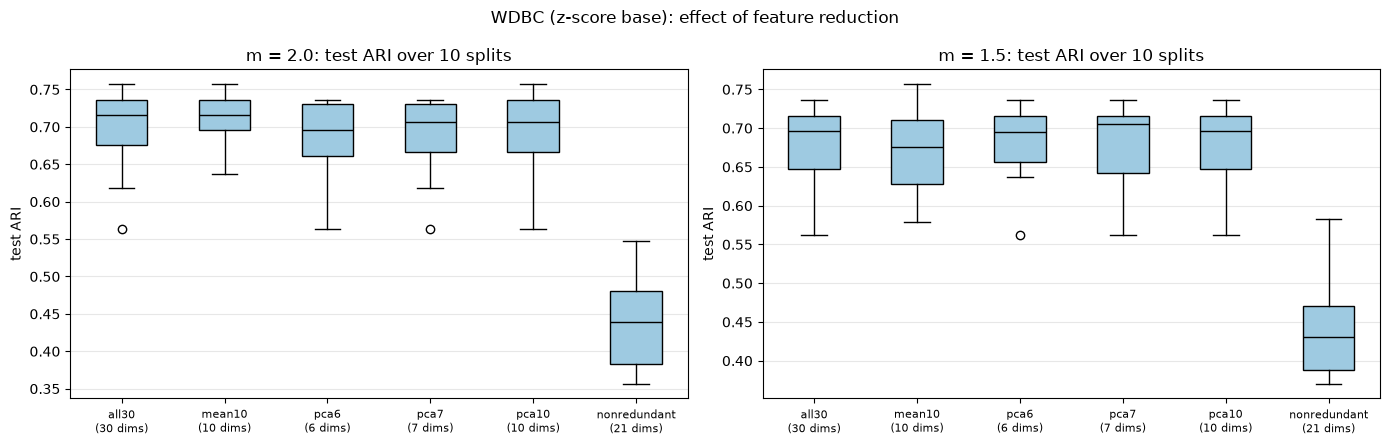

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, m in zip(axes, M_MAIN):
    g = red_split[red_split.m == m]
    ax.boxplot([g[g.feature_set == s]["test_ARI"] for s in FEATURE_SETS], patch_artist=True,
               boxprops={"facecolor": "#9ecae1"}, medianprops={"color": "black"})
    ax.set_xticks(range(1, len(FEATURE_SETS) + 1),
                  [f"{s}\n({reduced[s].shape[1]} dims)" for s in FEATURE_SETS], fontsize=8)
    ax.set_ylabel("test ARI")
    ax.set_title(f"m = {m}: test ARI over {N_SPLITS} splits")
    ax.grid(alpha=0.3, axis="y")
fig.suptitle("WDBC (z-score base): effect of feature reduction")
fig.tight_layout()
fig.savefig(FIG_DIR / "wdbc_reduced_split_ari.png", dpi=200)
plt.show()

## Step 9: Test: without scaling, does FCM group only by area?

Step 3a documents that the area features hold almost all of the raw variance. The claim that FCM on unscaled data would therefore group practically only by area was an inference, not a result. This step tests it.

- `raw_all30`: FCM on the unscaled 30 features.
- `raw_area3`: FCM on only `area_mean`, `area_se`, `area_worst` (unscaled).
- `raw_no_area27`: control, unscaled data without the 3 area features.
- `zscore_all30`: the z-score variant, for comparison.

If the claim holds, `raw_all30` and `raw_area3` should give almost the same partition (ARI and membership correlation close to 1).

In [39]:
from sklearn.metrics import adjusted_rand_score

AREA = ["area_mean", "area_se", "area_worst"]
area_idx = [list(FEATURES).index(f) for f in AREA]

# Documented part (Step 3a): share of the raw variance held by the area features
print("raw variance share of the area features:")
print(weights.loc[AREA, "raw (unscaled)"].round(4).to_string())
print("sum:", f"{weights.loc[AREA, 'raw (unscaled)'].sum():.2%}\n")

# Untested part: does FCM on the raw data group (almost) only by area?
# Same settings as the main runs: c = 2, m = 2, same seed, starts, eps, max_iter.
test_inputs = {
    "raw_all30":     X_raw,                                 # unscaled, all 30 features
    "raw_area3":     X_raw[:, area_idx],                    # unscaled, only the 3 area features
    "raw_no_area27": np.delete(X_raw, area_idx, axis=1),    # control: unscaled, area features removed
    "zscore_all30":  variants["zscore"],                    # the scaled variant used in the report
}

test_runs, rows = {}, []
for name, A in test_inputs.items():
    best, info = fcm.fcm_multistart(A, C_MAIN, m=2.0, n_init=N_INIT, seed=SEED,
                                    eps=FCM_EPS, max_iter=FCM_MAX_ITER)
    test_runs[name] = best
    scores, mapping = evaluation.external_scores(y, best.labels)
    rows.append({"input": name, "n_features": A.shape[1], **scores,
                 "iterations": best.n_iter, "n_at_best": info["n_at_best"],
                 "n_not_converged": info["n_not_converged"]})

area_test = pd.DataFrame(rows).set_index("input")

# Agreement between partitions: ARI of hard labels and |corr| of the memberships
# (c = 2, so one membership row is enough; abs() because cluster numbering is arbitrary)
for ref in ["raw_all30", "raw_area3"]:
    area_test[f"ARI_vs_{ref}"] = [adjusted_rand_score(test_runs[ref].labels, test_runs[n].labels)
                                  for n in area_test.index]
    area_test[f"abs_corr_U_vs_{ref}"] = [abs(np.corrcoef(test_runs[ref].U[0], test_runs[n].U[0])[0, 1])
                                         for n in area_test.index]

area_test.to_csv(OUT_DIR / "wdbc_scaling_area_test.csv")

for name in test_inputs:
    print(f"--- {name}: contingency with the diagnosis")
    print(evaluation.contingency(y, test_runs[name].labels), "\n")

print("raw_all30 prototypes, area features (original units):")
print(pd.DataFrame(test_runs["raw_all30"].V[:, area_idx], columns=AREA).round(1), "\n")

area_test.round(4)

raw variance share of the area features:
area_mean     0.2741
area_se       0.0046
area_worst    0.7173
sum: 99.60%

--- raw_all30: contingency with the diagnosis
class      B    M
cluster          
0        356   82
1          1  130 

--- raw_area3: contingency with the diagnosis
class      B    M
cluster          
0        356   82
1          1  130 

--- raw_no_area27: contingency with the diagnosis
class      B    M
cluster          
0        355   59
1          2  153 

--- zscore_all30: contingency with the diagnosis
class      B    M
cluster          
0         18  181
1        339   31 

raw_all30 prototypes, area features (original units):
   area_mean  area_se  area_worst
0      490.9     23.8       612.1
1     1194.5     94.2      1761.2 



,n_features,ARI,NMI,accuracy,recall_B,recall_M,iterations,n_at_best,n_not_converged,ARI_vs_raw_all30,abs_corr_U_vs_raw_all30,ARI_vs_raw_area3,abs_corr_U_vs_raw_area3
input,,,,,,,,,,,,,
raw_all30,30,0.4914,0.4648,0.8541,0.9972,0.6132,23,10,0,1.0000,1.0000,1.0000,1.0000
raw_area3,3,0.4914,0.4648,0.8541,0.9972,0.6132,23,10,0,1.0000,1.0000,1.0000,1.0000
raw_no_area27,27,0.6114,0.5515,0.8928,0.9944,0.7217,25,10,0,0.8278,0.9687,0.8278,0.9685
zscore_all30,30,0.6829,0.5612,0.9139,0.9496,0.8538,26,10,0,0.5031,0.7869,0.5031,0.7866
